<a href="https://colab.research.google.com/github/GarzonDiegoINL/Characterization/blob/main/EIS_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EIS Analysis — BioLogic `.mpr` Files

**Workflow:**
1. Load binary `.mpr` data via `galvani` (same as the NOMAD plugin)
2. Optionally extract metadata via `yadg`
3. Preprocess data (remove inductive artefacts)
4. Validate with Kramers-Kronig
5. Fit a multi-RC equivalent circuit with bounded CPE elements using `impedance.py`
6. Generate publication-quality Nyquist + residual plots

**Circuit string syntax** (impedance.py):  
- 2 arcs: `R0-p(R1,CPE1)-p(R2,CPE2)`  
- 3 arcs: `R0-p(R1,CPE1)-p(R2,CPE2)-p(R3,CPE3)`  
- `R` = resistor, `CPE(Q, α)` = Constant Phase Element where $Z = \frac{1}{Q(j2\pi f)^\alpha}$

In [5]:
!pip install galvani impedance yadg pyDRTtools cvxopt PyQt5
!pip install pyDRTtools

In [6]:
from __future__ import annotations

import json
import os
import warnings
from pathlib import Path

# ── Headless Qt: must be set before any Qt / pyDRTtools import ────────────────
# pyDRTtools/__init__.py imports its GUI module, which loads PyQt5.  Setting
# QT_QPA_PLATFORM=offscreen lets PyQt5 initialise without a physical display
# (no window is ever opened — the GUI is never launched).
os.environ.setdefault("QT_QPA_PLATFORM", "offscreen")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.ticker import LogLocator, LogFormatter
from scipy.signal import find_peaks

from galvani import MPRfile
from impedance.models.circuits import CustomCircuit
from impedance import preprocessing
from impedance.validation import linKK

# ── pyDRTtools — Tikhonov-regularised DRT ────────────────────────────────────
# Import the runs sub-module directly to avoid triggering the Qt GUI window.
# The package __init__ still imports PyQt5 (caught safely with the env-var above).
try:
    from pyDRTtools.runs import EIS_object, simple_run as drt_simple_run
    _DRT_AVAILABLE = True
except ImportError:
    _DRT_AVAILABLE = False
    print("⚠  pyDRTtools not installed — DRT section will be skipped.\n"
          "   Run:  !pip install pyDRTtools cvxopt PyQt5")

warnings.filterwarnings("ignore", category=RuntimeWarning)

plt.rcParams.update({
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 13,
    "legend.fontsize": 11,
    "figure.dpi": 120,
})

print("All imports OK.")


All imports OK.


---
## 1 — Data Loading

The `load_mpr` function mirrors the NOMAD plugin's `MPRParser`:
- **`galvani`** reads the binary `.mpr` measurement data (columns depend on technique; EIS uses `freq/Hz`, `Re(Z)/Ohm`, `-Im(Z)/Ohm`)
- **`yadg`** (optional) extracts the settings block — electrode area, material, electrolyte, comments

The complex impedance is assembled as $$Z = \text{Re}(Z) - j \cdot \bigl(-\text{Im}(Z)\bigr)$$ because BioLogic EC-Lab stores the sign-flipped imaginary part as the column `-Im(Z)/Ohm`.

In [3]:
from __future__ import annotations


def load_mpr(filepath: str | Path) -> tuple[np.ndarray, np.ndarray, pd.DataFrame, dict]:
    """Load a BioLogic .mpr EIS file.

    Uses `galvani` for measurement data (same as the NOMAD MPRParser plugin)
    and `yadg` (optional) for the settings metadata block.

    Parameters
    ----------
    filepath : str or Path
        Path to the `.mpr` binary file.

    Returns
    -------
    frequencies : np.ndarray
        Frequency array in Hz (descending, as measured).
    Z : np.ndarray of dtype complex128
        Complex impedance array.  Re(Z) - j*Im(Z) in Ohm.
    df_raw : pd.DataFrame
        Raw DataFrame from galvani containing all logged columns.
    metadata : dict
        Settings extracted by yadg (empty dict if yadg is unavailable or fails).
    """
    filepath = Path(filepath)

    # ── 1. Measurement data via galvani ──────────────────────────────────────
    mpr = MPRfile(str(filepath))
    df_raw = pd.DataFrame(mpr.data)

    required = {"freq/Hz", "Re(Z)/Ohm", "-Im(Z)/Ohm"}
    missing = required - set(df_raw.columns)
    if missing:
        raise ValueError(
            f"File does not appear to be an EIS measurement. "
            f"Missing columns: {missing}\n"
            f"Available columns: {list(df_raw.columns)}"
        )

    frequencies = df_raw["freq/Hz"].to_numpy(dtype=np.float64)
    # BioLogic stores -Im(Z), so: Z = Re - j*(-Im(Z)/Ohm) = Re + j*Im
    # But impedance.py convention: Im(Z) < 0 for capacitive → Z = Re - j*|Im|
    Z = (
        df_raw["Re(Z)/Ohm"].to_numpy(dtype=np.float64)
        - 1j * df_raw["-Im(Z)/Ohm"].to_numpy(dtype=np.float64)
    )

    # ── 2. Metadata via yadg (optional) ──────────────────────────────────────
    metadata: dict = {}
    try:
        import yadg

        dt = yadg.extractors.extract(
            filetype="eclab.mpr", path=filepath, timezone="UTC"
        )
        raw_meta = json.loads(dt.attrs.get("original_metadata", "{}"))
        settings = raw_meta.get("settings", raw_meta)
        for key in (
            "electrode_area",
            "electrode_material",
            "electrolyte",
            "reference_electrode",
            "comments",
        ):
            val = settings.get(key)
            if val:
                metadata[key] = val
    except Exception as exc:
        print(f"[yadg] metadata extraction skipped: {exc}")

    return frequencies, Z, df_raw, metadata

---
## 2 — Load Data & Preview

In [4]:
# ── Google Colab file upload ─────────────────────────────────────────────────
# When running in Colab, this cell shows a file-picker widget and sets FILE_PATH
# automatically.  Running locally, it just confirms the path from the config cell.
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import files as _colab_files
    print("Running in Google Colab — please upload your .mpr file:")
    _uploaded = _colab_files.upload()        # shows the upload widget
    if _uploaded:
        FILE_PATH = list(_uploaded.keys())[0]
        print(f"\n✔  FILE_PATH set to: '{FILE_PATH}'")
    else:
        print("⚠  No file uploaded. Set FILE_PATH manually in the configuration cell.")
else:
    print(f"Running locally.  FILE_PATH = '{FILE_PATH}'")
    print("(In Google Colab this cell will display a file-upload widget.)")

Running in Google Colab — please upload your .mpr file:


Saving IV_EIS_IV_MS_0to18_02_SPEIS_C03.mpr to IV_EIS_IV_MS_0to18_02_SPEIS_C03 (1).mpr

✔  FILE_PATH set to: 'IV_EIS_IV_MS_0to18_02_SPEIS_C03 (1).mpr'


In [7]:
_, _, df_raw, metadata = load_mpr(FILE_PATH)

# ── Print metadata ────────────────────────────────────────────────────────────
print("═" * 56)
print(f"  File : {Path(FILE_PATH).name}")
if metadata:
    print("  Metadata from yadg:")
    for k, v in metadata.items():
        print(f"    {k}: {v}")
else:
    print("  No yadg metadata.")
print("═" * 56)

# ── Detect single EIS vs SPEIS (multiple voltage steps) ──────────────────────
if "cycle number" in df_raw.columns and df_raw["cycle number"].nunique() > 1:
    IS_SPEIS = True
    cycles_in_file = sorted(df_raw["cycle number"].unique())
    spectra_all = {}
    for cyc in cycles_in_file:
        sub = df_raw[df_raw["cycle number"] == cyc]
        freq = sub["freq/Hz"].to_numpy(np.float64)
        Z = (sub["Re(Z)/Ohm"].to_numpy(np.float64)
             - 1j * sub["-Im(Z)/Ohm"].to_numpy(np.float64))
        valid = freq > 0          # drop any bookkeeping rows with f = 0
        freq, Z = freq[valid], Z[valid]
        voltage = float(sub["<Ewe>/V"].mean()) if "<Ewe>/V" in sub.columns else np.nan
        spectra_all[cyc] = {"freq": freq, "Z": Z, "voltage": voltage}

    print(f"SPEIS file detected — {len(spectra_all)} voltage steps:")
    print(f"  {'Cycle':>7}  {'Voltage (V)':>12}  {'Points':>7}")
    for cyc, sp in spectra_all.items():
        print(f"  {cyc:>7.0f}  {sp['voltage']:>12.4f}  {len(sp['freq']):>7}")
else:
    IS_SPEIS = False
    freq_all = df_raw["freq/Hz"].to_numpy(np.float64)
    Z_all = (df_raw["Re(Z)/Ohm"].to_numpy(np.float64)
             - 1j * df_raw["-Im(Z)/Ohm"].to_numpy(np.float64))
    spectra_all = {1: {"freq": freq_all, "Z": Z_all, "voltage": np.nan}}
    print(f"Single EIS spectrum — {len(freq_all)} points,  "
          f"f = {freq_all.min():.3g} – {freq_all.max():.3g} Hz")

[yadg] metadata extraction skipped: 45
════════════════════════════════════════════════════════
  File : IV_EIS_IV_MS_0to18_02_SPEIS_C03 (1).mpr
  No yadg metadata.
════════════════════════════════════════════════════════
SPEIS file detected — 19 voltage steps:
    Cycle   Voltage (V)   Points
        1        0.0002       79
        2        0.1001       79
        3        0.2001       79
        4        0.3001       79
        5        0.4001       79
        6        0.5001       79
        7        0.6001       79
        8        0.7001       79
        9        0.8001       79
       10        0.9000       79
       11        1.0000       79
       12        1.1001       79
       13        1.2001       79
       14        1.3000       79
       15        1.4001       79
       16        1.5000       79
       17        1.6000       79
       18        1.6999       79
       19        1.8000       79


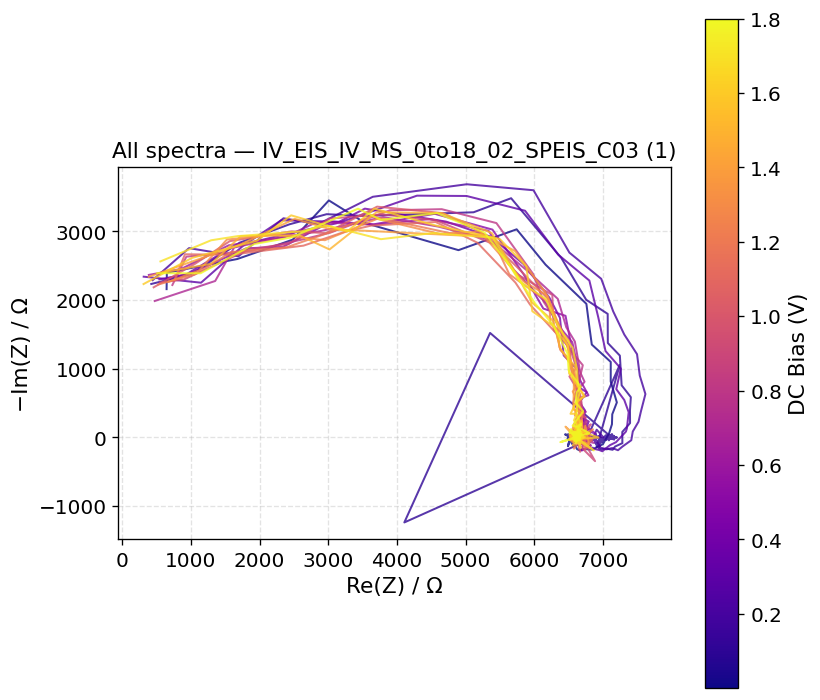

In [30]:
# ── Overview Nyquist: all raw spectra overlaid, coloured by voltage ───────────
v_vals_all = [sp["voltage"] for sp in spectra_all.values()]
cmap_ov = plt.cm.plasma
v_lo, v_hi = min(v_vals_all), max(v_vals_all)
norm_ov = plt.Normalize(v_lo, v_hi) if v_lo != v_hi else plt.Normalize(v_lo - 1, v_hi + 1)

fig, ax = plt.subplots(figsize=(7, 6))
for cyc, sp in spectra_all.items():
    color = cmap_ov(norm_ov(sp["voltage"])) if np.isfinite(sp["voltage"]) else "steelblue"
    ax.plot(sp["Z"].real, -sp["Z"].imag, "-", lw=1.2, color=color, alpha=0.8)

sm = plt.cm.ScalarMappable(cmap=cmap_ov, norm=norm_ov)
sm.set_array([])
fig.colorbar(sm, ax=ax, label="DC Bias (V)")
ax.set_xlabel("Re(Z) / Ω", fontsize=13)
ax.set_ylabel("−Im(Z) / Ω", fontsize=13)
ax.set_title(f"All spectra — {Path(FILE_PATH).stem}", fontsize=13)
ax.grid(True, linestyle="--", alpha=0.35)
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.savefig("all_spectra.png")
plt.show()

---
## 4 — Preprocessing

Two filters are applied:

1. **`ignoreBelowX`** — removes data points where Re(Z) < 0, which arise from high-frequency inductive artefacts (parasitic wiring inductance).
2. **Frequency crop** — optional window defined by `F_MIN` / `F_MAX` in the configuration cell.

The Nyquist scatter below helps judge whether the raw data is clean.

  Cycle 1  (+0.0002 V):  79 → 35 pts  (removed 44)
  Cycle 2  (+0.1001 V):  79 → 37 pts  (removed 42)
  Cycle 3  (+0.2001 V):  79 → 39 pts  (removed 40)
  Cycle 4  (+0.3001 V):  79 → 40 pts  (removed 39)
  Cycle 5  (+0.4001 V):  79 → 56 pts  (removed 23)
  Cycle 6  (+0.5001 V):  79 → 58 pts  (removed 21)
  Cycle 7  (+0.6001 V):  79 → 52 pts  (removed 27)
  Cycle 8  (+0.7001 V):  79 → 47 pts  (removed 32)
  Cycle 9  (+0.8001 V):  79 → 56 pts  (removed 23)
  Cycle 10  (+0.9000 V):  79 → 61 pts  (removed 18)
  Cycle 11  (+1.0000 V):  79 → 56 pts  (removed 23)
  Cycle 12  (+1.1001 V):  79 → 59 pts  (removed 20)
  Cycle 13  (+1.2001 V):  79 → 54 pts  (removed 25)
  Cycle 14  (+1.3000 V):  79 → 55 pts  (removed 24)
  Cycle 15  (+1.4001 V):  79 → 52 pts  (removed 27)
  Cycle 16  (+1.5000 V):  79 → 58 pts  (removed 21)
  Cycle 17  (+1.6000 V):  79 → 54 pts  (removed 25)
  Cycle 18  (+1.6999 V):  79 → 48 pts  (removed 31)
  Cycle 19  (+1.8000 V):  79 → 57 pts  (removed 22)

Ready to fit 19 spec

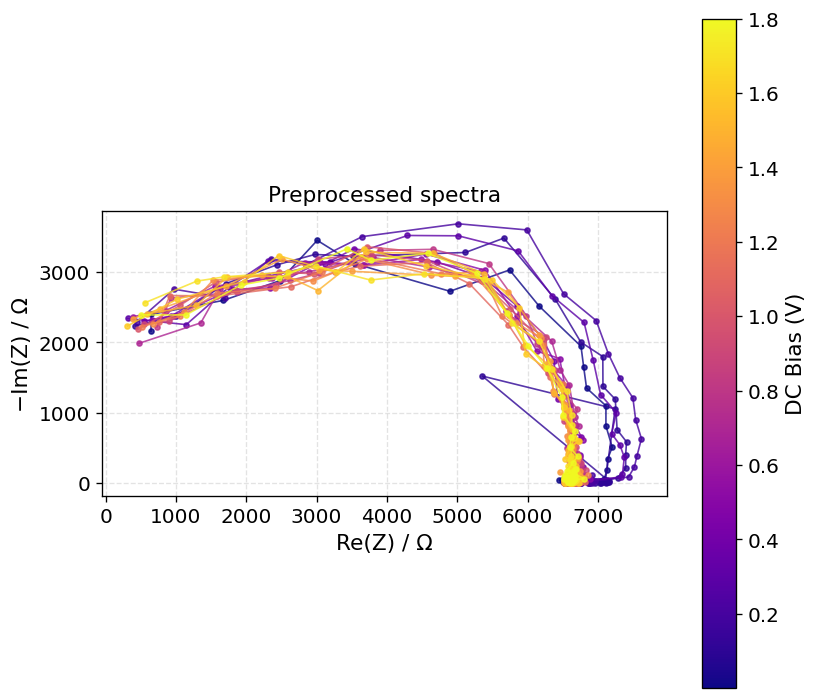

In [14]:
CYCLES_TO_FIT = 'all'

# ── Frequency window (Hz) — set None to keep all data ────────────────────────
F_MIN = None    # e.g. 1e-2
F_MAX = None    # e.g. 1e6

# ── Select which cycles to process ───────────────────────────────────────────
if CYCLES_TO_FIT == "all":
    selected_cycles = list(spectra_all.keys())
else:
    selected_cycles = [c for c in CYCLES_TO_FIT if c in spectra_all]
    missing = [c for c in CYCLES_TO_FIT if c not in spectra_all]
    if missing:
        print(f"Warning: cycles not found in file: {missing}")

# ── Apply filters to every selected spectrum ──────────────────────────────────
clean_spectra = {}
for cyc in selected_cycles:
    sp = spectra_all[cyc]
    freq, Z = sp["freq"], sp["Z"]
    n_raw_sp = len(freq)

    # Step 1: remove inductive artefacts (Re(Z) < 0)
    freq_f, Z_f = preprocessing.ignoreBelowX(freq, Z)

    # Step 2: optional frequency crop
    if F_MIN is not None or F_MAX is not None:
        f_lo = F_MIN if F_MIN is not None else 0.0
        f_hi = F_MAX if F_MAX is not None else np.inf
        mask = (freq_f >= f_lo) & (freq_f <= f_hi)
        freq_f, Z_f = freq_f[mask], Z_f[mask]

    clean_spectra[cyc] = {"freq": freq_f, "Z": Z_f, "voltage": sp["voltage"]}
    v_str = f"{sp['voltage']:+.4f} V" if np.isfinite(sp["voltage"]) else "N/A"
    print(f"  Cycle {cyc:.0f}  ({v_str}):  "
          f"{n_raw_sp} → {len(freq_f)} pts  (removed {n_raw_sp - len(freq_f)})")

print(f"\nReady to fit {len(clean_spectra)} spectra.")

# ── Preprocessed Nyquist preview (overlaid) ───────────────────────────────────
v_vals_c = [sp["voltage"] for sp in clean_spectra.values()]
norm_c = plt.Normalize(min(v_vals_c), max(v_vals_c)) if min(v_vals_c) != max(v_vals_c) \
         else plt.Normalize(min(v_vals_c) - 1, max(v_vals_c) + 1)
cmap_c = plt.cm.plasma

fig, ax = plt.subplots(figsize=(7, 6))
for cyc, sp in clean_spectra.items():
    color = cmap_c(norm_c(sp["voltage"])) if np.isfinite(sp["voltage"]) else "steelblue"
    ax.plot(sp["Z"].real, -sp["Z"].imag, "o-", ms=3, lw=1, color=color, alpha=0.8)

sm2 = plt.cm.ScalarMappable(cmap=cmap_c, norm=norm_c)
sm2.set_array([])
fig.colorbar(sm2, ax=ax, label="DC Bias (V)")
ax.set_xlabel("Re(Z) / Ω", fontsize=13)
ax.set_ylabel("−Im(Z) / Ω", fontsize=13)
ax.set_title("Preprocessed spectra", fontsize=13)
ax.grid(True, linestyle="--", alpha=0.35)
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.savefig("preprocessed_spectra.png")
plt.show()

---
## 5a — Kramers-Kronig Validation

The **Linear Kramers-Kronig (Lin-KK)** test checks whether the data is causal, linear, and stable — the three prerequisites for valid EIS. Residuals should be flat and within ±2 % across the full frequency range. Larger systematic deviations indicate drift, non-linearity, or artefacts.

Lin-KK: M = 8,  μ = 0.7459  (< 0.5 = good)


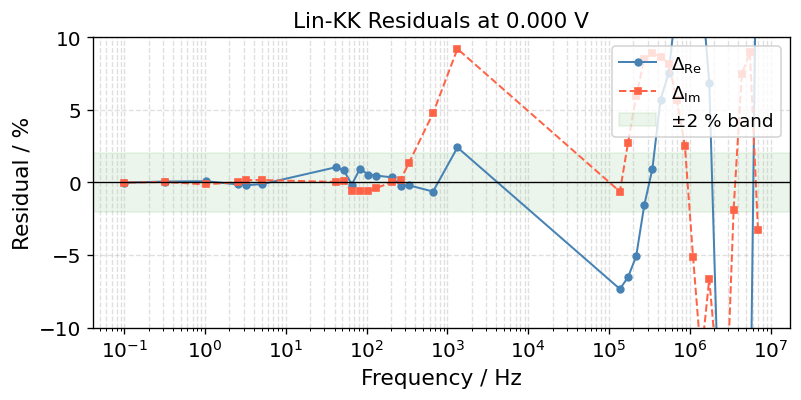

Lin-KK: M = 8,  μ = 0.8320  (< 0.5 = good)


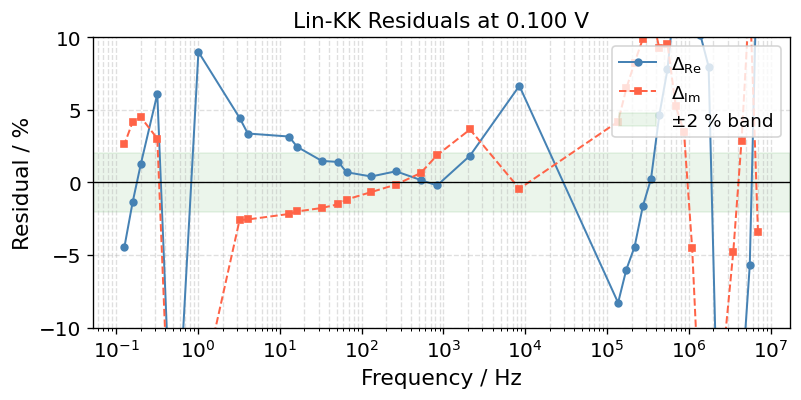

Lin-KK: M = 7,  μ = 0.8462  (< 0.5 = good)


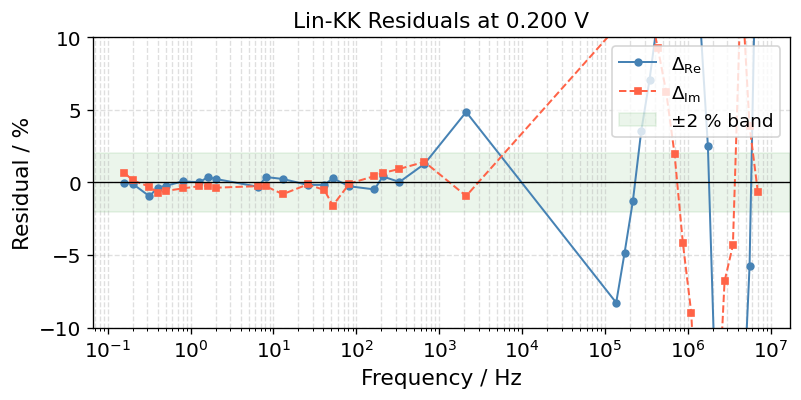

Lin-KK: M = 8,  μ = 0.8187  (< 0.5 = good)


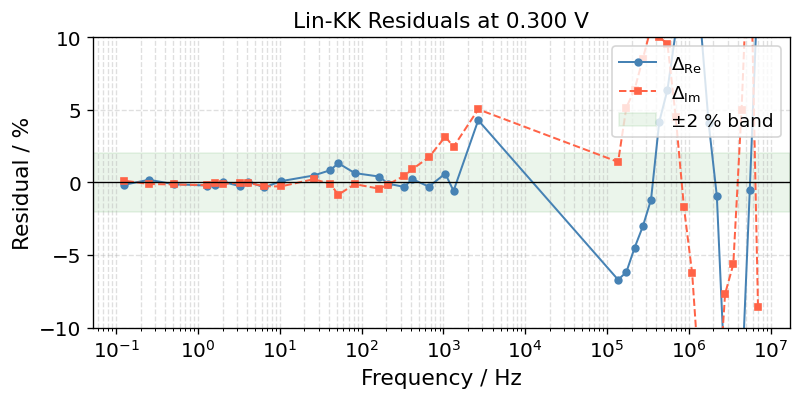

10 0.8896939117981998 276.6607302638219
Lin-KK: M = 12,  μ = 0.8473  (< 0.5 = good)


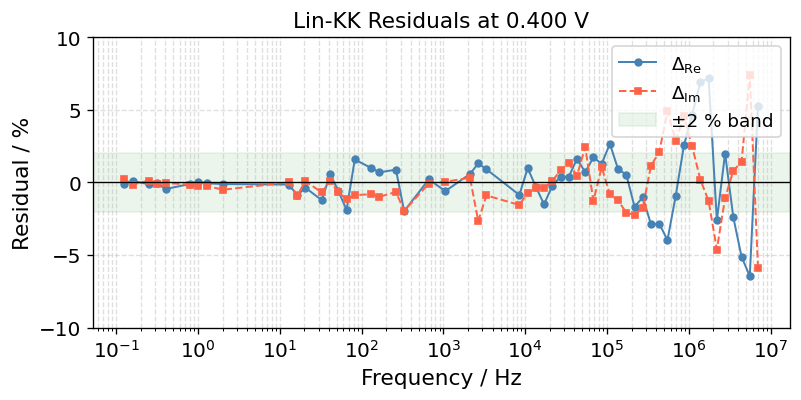

10 0.8864545532132952 266.83714529602395
Lin-KK: M = 15,  μ = 0.8243  (< 0.5 = good)


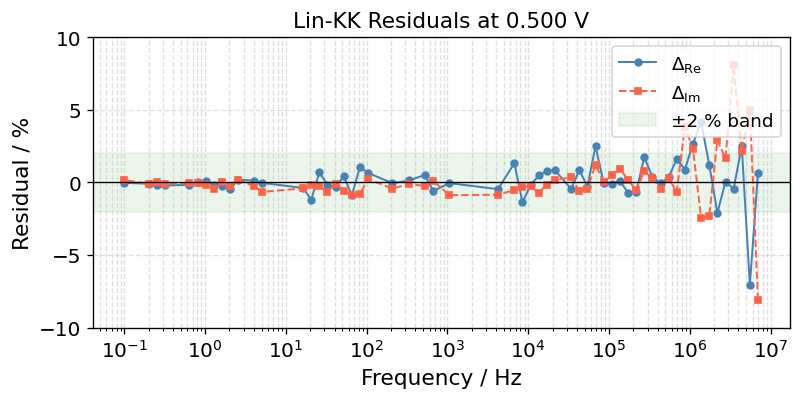

10 0.8893111709209425 271.6157494372792
Lin-KK: M = 17,  μ = 0.8158  (< 0.5 = good)


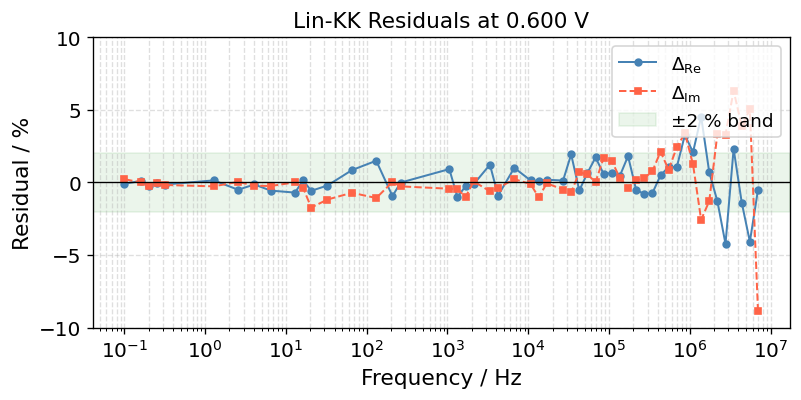

10 0.8685607094660714 294.1754454135604
Lin-KK: M = 12,  μ = 0.8468  (< 0.5 = good)


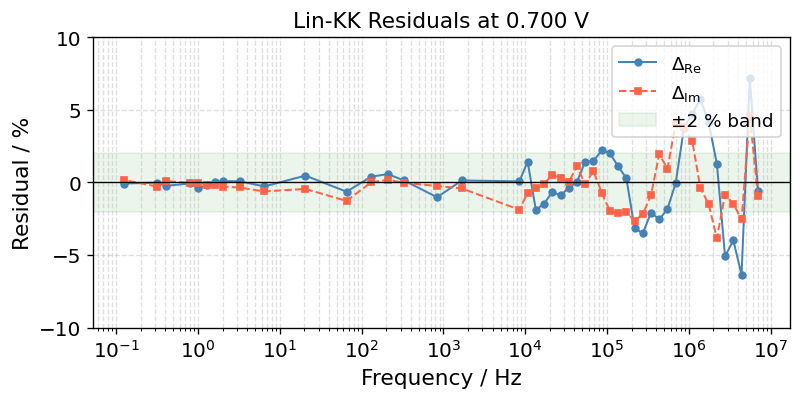

10 0.8892497408312018 282.2283137359474
Lin-KK: M = 12,  μ = 0.8281  (< 0.5 = good)


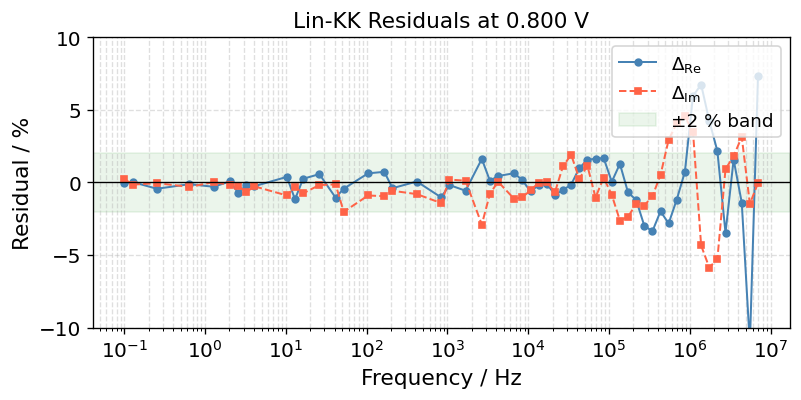

10 0.8970674389666595 254.80736484605413
Lin-KK: M = 12,  μ = 0.8488  (< 0.5 = good)


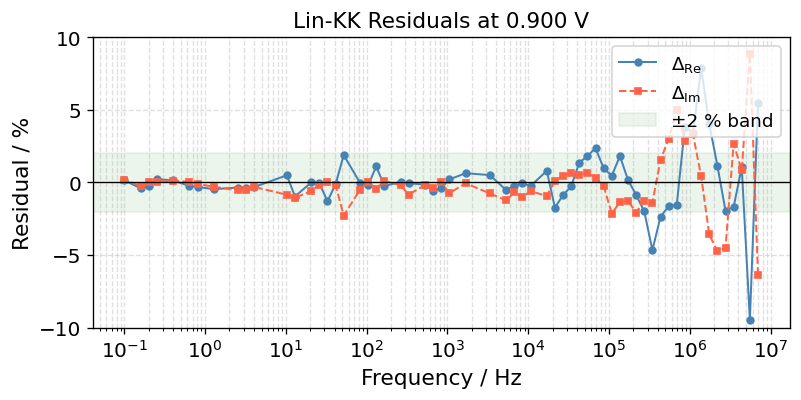

10 0.8855129480672042 270.70516759336715
Lin-KK: M = 11,  μ = 0.8432  (< 0.5 = good)


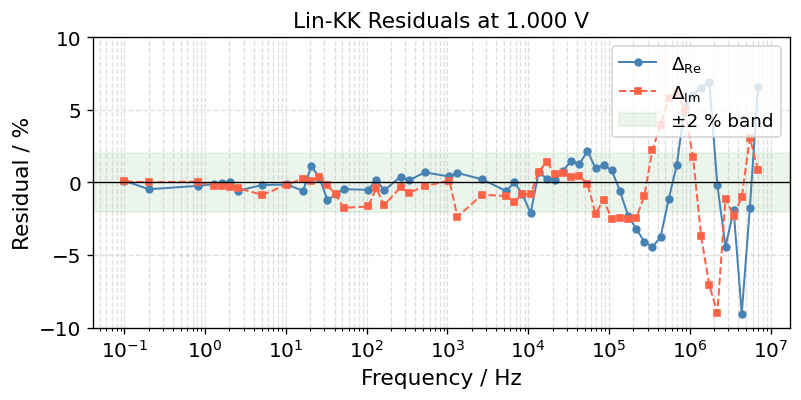

10 0.8960066631907839 234.16233999771933
Lin-KK: M = 17,  μ = 0.8404  (< 0.5 = good)


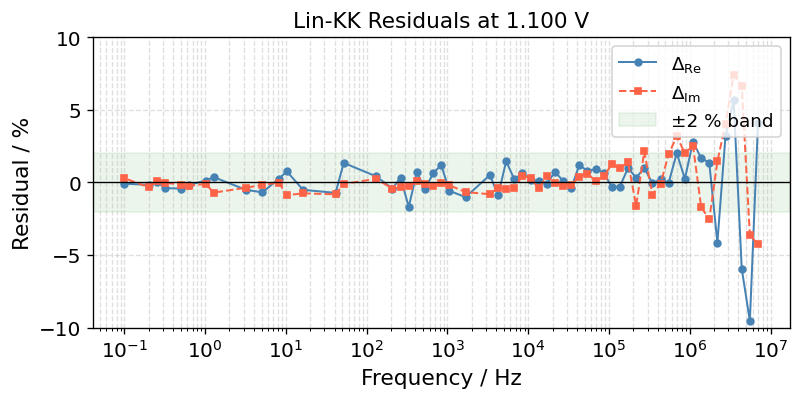

10 0.8801493052596241 255.827669439332
Lin-KK: M = 18,  μ = 0.7627  (< 0.5 = good)


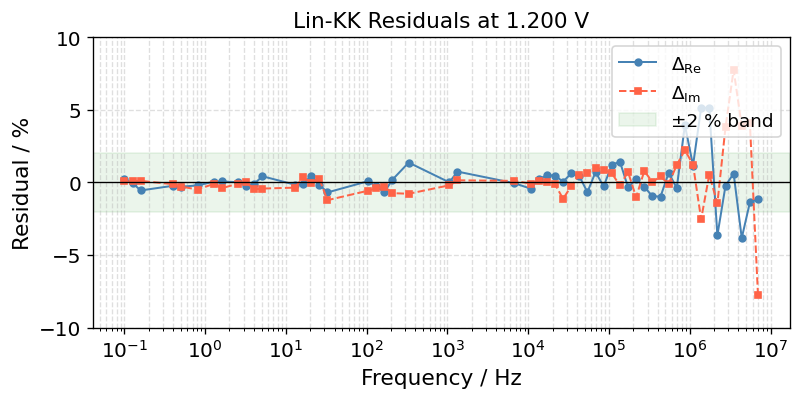

10 0.8877636978958369 278.405302819655
Lin-KK: M = 12,  μ = 0.8300  (< 0.5 = good)


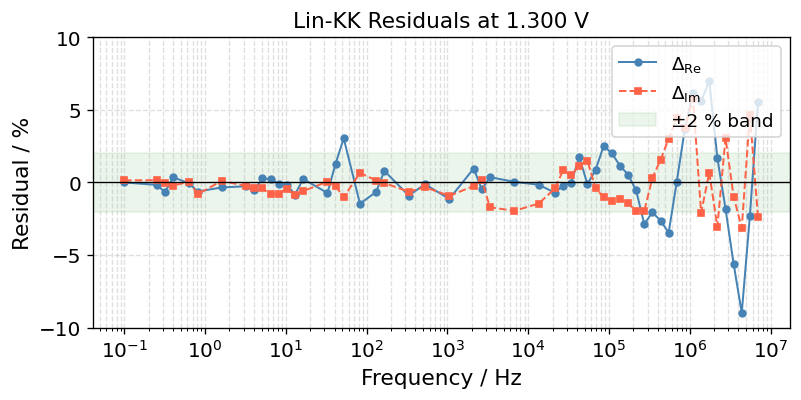

10 0.8994320087271387 258.571244375702
Lin-KK: M = 17,  μ = 0.8410  (< 0.5 = good)


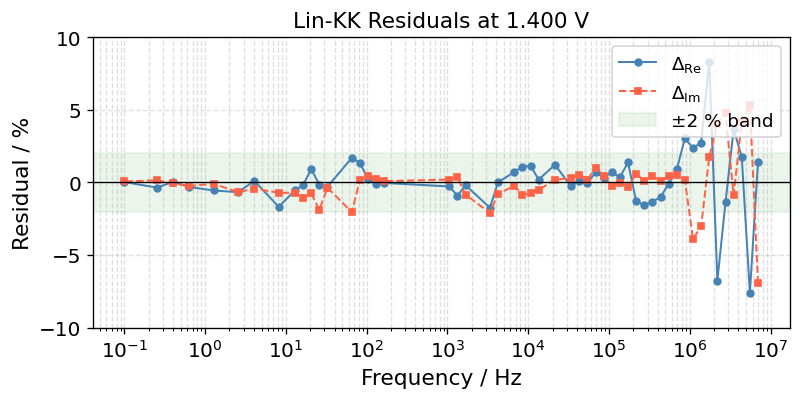

10 0.8884241812424647 241.65059671567718
Lin-KK: M = 16,  μ = 0.7833  (< 0.5 = good)


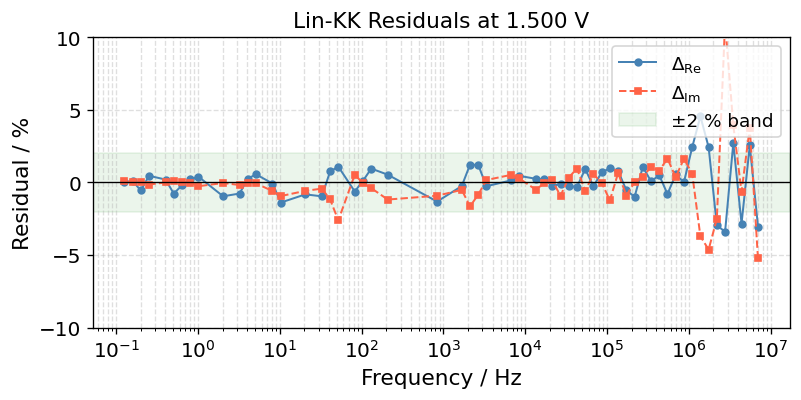

10 0.9158560023161426 231.2863902875365
Lin-KK: M = 18,  μ = 0.8018  (< 0.5 = good)


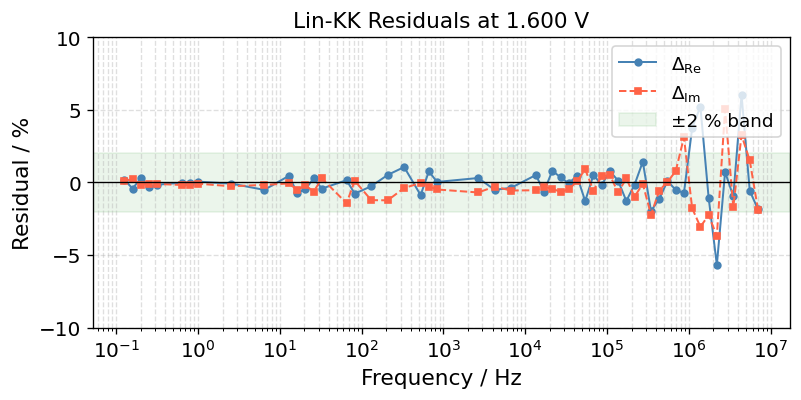

10 0.8882263195741459 221.8313634412183
Lin-KK: M = 16,  μ = 0.8406  (< 0.5 = good)


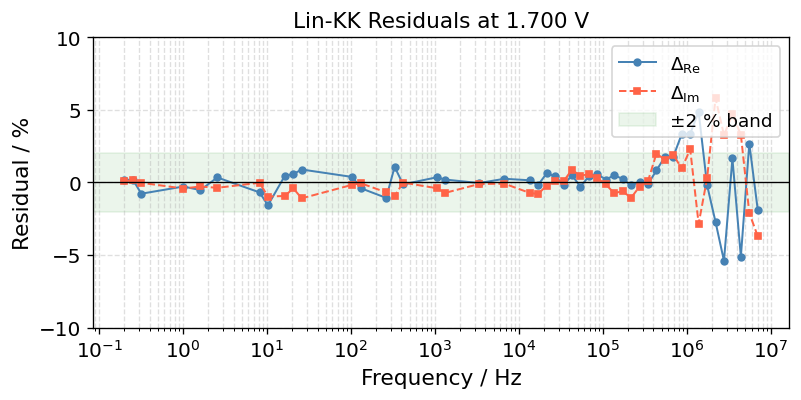

10 0.9007897359783194 238.76831624449855
Lin-KK: M = 12,  μ = 0.8453  (< 0.5 = good)


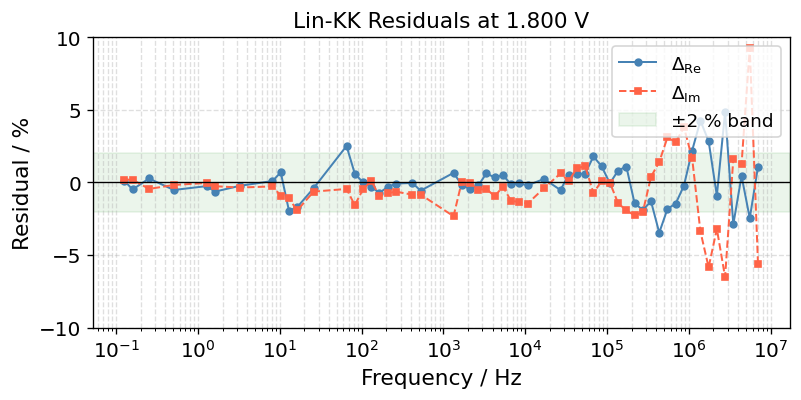

In [10]:
import impedance.validation as _iv
from impedance.models.circuits.elements import circuit_elements as _ce
_ce["np"] = np

for cyc, sp in clean_spectra.items():
    frequencies_clean = sp["freq"]
    Z_clean = sp["Z"]

    M, mu, Z_linKK, res_real, res_imag = linKK(
        frequencies_clean, Z_clean, c=0.85, max_M=50, fit_type="complex", add_cap=True
    )

    print(f"Lin-KK: M = {M},  μ = {mu:.4f}  (< 0.5 = good)")

    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.semilogx(frequencies_clean, res_real * 100, "o-", ms=4, lw=1.2,
                color="steelblue", label=r"$\Delta_\mathrm{Re}$")
    ax.semilogx(frequencies_clean, res_imag * 100, "s--", ms=4, lw=1.2,
                color="tomato", label=r"$\Delta_\mathrm{Im}$")
    ax.axhline(0, color="black", lw=0.8)
    ax.axhspan(-2, 2, alpha=0.08, color="green", label="±2 % band")
    ax.set_xlabel("Frequency / Hz")
    ax.set_ylabel("Residual / %")
    ax.set_title(f"Lin-KK Residuals at {round(sp['voltage'], 3):.3f} V")
    ax.legend(loc="upper right")
    ax.grid(True, which="both", linestyle="--", alpha=0.4)
    ax.set_ylim(-10, 10)
    plt.tight_layout()
    plt.show()

---
## 5b — Distribution of Relaxation Times (DRT) — Stage 1

The DRT deconvolution transforms the raw impedance spectrum into a distribution
$\gamma(\ln\tau)$ that represents the contribution of every relaxation process
at timescale $\tau$:

$$Z(\omega) = R_\infty + \int_{-\infty}^{+\infty}
\frac{\gamma(\ln\tau)}{1 + j\omega\tau}\,d\ln\tau$$

**Why run DRT before ECM fitting?**

| Problem with manual guesses | DRT solution |
|---|---|
| $R_i$ initial guess is orders of magnitude off | area under peak $i$ ≈ $R_i$ |
| Number of RC arcs is unknown | count the distinct peaks in $\gamma(\tau)$ |
| Optimizer lands in local minimum | tight, data-driven bounds from $R_i$, $\tau_i$ |

**Workflow in this section**

1. **DRT config cell** — set regularisation method and peak-finder sensitivity.
2. **DRT fit loop** — runs `pyDRTtools.runs.simple_run` (Tikhonov / ridge
   regression with a Gaussian RBF discretisation) on every SPEIS spectrum.
   Peaks are extracted with `scipy.signal.find_peaks`; for each peak:
   $$R_i = \int_{\text{peak}\,i} \gamma(\ln\tau)\,d\ln\tau, \quad
   \tau_i = \tau\big|_{\gamma\,\text{max}}, \quad
   Q_i = \frac{\tau_i^{\,\alpha}}{R_i}$$
3. **DRT plot** — $\gamma(\tau)$ vs $\tau$ for all voltage steps, coloured by DC bias.
4. **Suggestion cell** — prints copy-pasteable `INITIAL_GUESS_ALL` and `N_RC`
   values derived from the reference spectrum (closest to 0 V).

After reviewing the suggestions, paste them into the **USER CONFIGURATION** cell
(Section 2) and re-run from there downward — no need to re-run DRT.


In [11]:
# ═══════════════════════════════════════════════════════════════════
#  DRT CONFIGURATION — edit values in this cell
# ═══════════════════════════════════════════════════════════════════

# ── Expected number of dominant RC processes ──────────────────────────────────
# Used to set the peak-finder sensitivity (not a hard constraint: the finder
# may return fewer peaks if the DRT is flat, or more if N_DRT_PEAKS is large).
N_DRT_PEAKS = 1

# ── Regularisation parameter selection ───────────────────────────────────────
# 'GCV'    → Generalised cross-validation (recommended; auto-selects λ per spectrum)
# 'LC'     → L-curve criterion
# 'custom' → fix λ to DRT_LAMBDA (fastest — skip the optimisation loop)
DRT_CV_TYPE = "LC"
DRT_LAMBDA  = 1e-3      # only active when DRT_CV_TYPE == 'custom'

# ── CPE exponent assumed when computing Q from (R, τ) ────────────────────────
# Q_i = τ_i^α / R_i  (exact for a ZARC element; α=0.85 is a typical default)
# Adjust here if you know a better estimate from prior fits.
DRT_ALPHA_ASSUMED = 0.85

# ── Peak-detection sensitivity ────────────────────────────────────────────────
# Peaks below  DRT_PEAK_PROMINENCE_FRAC × γ_max  are ignored on the first pass.
# If fewer than N_DRT_PEAKS are found, the threshold is automatically lowered.
DRT_PEAK_PROMINENCE_FRAC = 0.05   # fraction of γ_max
DRT_PEAK_MIN_DISTANCE    = 3      # minimum separation between peaks (array samples)


In [17]:
# ── Stage 1: DRT deconvolution for all SPEIS spectra ─────────────────────────
# Sign convention note:
#   impedance.py stores Z with Im(Z) < 0 for capacitive arcs.
#   pyDRTtools EIS_object expects Z_double_prime = −Im(Z) > 0 for capacitive.
#   → pass (freq, Z.real, −Z.imag) to EIS_object.
#
# Robustness notes:
#   • cvxopt solver failure → spectrum skipped (entry stored as None).
#   • Fewer peaks than N_DRT_PEAKS → prominence threshold is lowered, then the
#     N_DRT_PEAKS tallest peaks are kept.
#   • Zero peaks found → the spectrum is stored with an empty drt_peaks list.

if not _DRT_AVAILABLE:
    print("pyDRTtools not available — install it and re-run the imports cell.")
else:
    print("Running DRT deconvolution …\n")
    _alpha = DRT_ALPHA_ASSUMED
    _prev_peaks = []    # fallback: carry forward last successful peaks

    for cyc, sp in clean_spectra.items():
        freq = sp["freq"]
        Z    = sp["Z"]
        v    = sp["voltage"]
        v_str = f"{v:+.4f} V" if np.isfinite(v) else f"cycle {cyc:.0f}"

        # ── Build pyDRTtools data container ───────────────────────────────────
        entry = EIS_object(freq, Z.real, -Z.imag)

        # ── Tikhonov-regularised DRT ──────────────────────────────────────────
        try:
            entry = drt_simple_run(
                entry,
                rbf_type="Gaussian",
                data_used="Combined Re-Im Data",
                induct_used=1,          # inductance column absorbs high-freq artefacts
                der_used="1st order",
                cv_type=DRT_CV_TYPE,
                reg_param=DRT_LAMBDA,
                shape_control="FWHM Coefficient",
                coeff=0.5,
            )
        except Exception as exc:
            print(f"  {v_str}: DRT FAILED — {exc}")
            sp["drt"]       = None
            sp["drt_peaks"] = []
            continue

        gamma    = entry.gamma
        tau_fine = entry.out_tau_vec

        # ── Peak detection ────────────────────────────────────────────────────
        min_prom = DRT_PEAK_PROMINENCE_FRAC * gamma.max()
        peak_idx, _ = find_peaks(gamma,
                                 prominence=min_prom,
                                 distance=DRT_PEAK_MIN_DISTANCE)

        # Fallback 1: prominence too tight — lower it and retry
        if len(peak_idx) < N_DRT_PEAKS:
            peak_idx, _ = find_peaks(gamma, distance=DRT_PEAK_MIN_DISTANCE)

        # Fallback 2: keep only the N_DRT_PEAKS tallest peaks
        if len(peak_idx) > N_DRT_PEAKS:
            heights  = gamma[peak_idx]
            peak_idx = peak_idx[np.argsort(heights)[-N_DRT_PEAKS:]]
            peak_idx = np.sort(peak_idx)   # restore τ order (ascending τ)

        # ── Integrate area under each peak → R_i ─────────────────────────────
        log_tau   = np.log(tau_fine)
        drt_peaks = []
        for pid in peak_idx:
            # Find flanking 10 %-height points as integration boundaries
            thresh = gamma[pid] * 0.1
            left   = pid - next((j for j, v in enumerate(gamma[pid::-1]) if v < thresh), pid)
            right  = pid + next((j for j, v in enumerate(gamma[pid:])    if v < thresh), len(gamma) - pid - 1)
            left   = max(0, left)
            right  = min(len(gamma) - 1, right)

            R_i   = float(np.trapezoid(gamma[left:right + 1], log_tau[left:right + 1]))
            R_i   = max(R_i, 1e-3)   # clamp numerical negatives
            tau_i = float(tau_fine[pid])
            C_i   = tau_i / R_i
            Q_i   = (tau_i ** _alpha) / R_i   # ZARC relation: Q = τ^α / R

            drt_peaks.append({"R": R_i, "tau": tau_i, "C_eff": C_i, "Q": Q_i})

        # Fallback 3: no peaks found → reuse previous cycle's peaks (warm carry)
        if not drt_peaks and _prev_peaks:
            drt_peaks = _prev_peaks
            print(f"  {v_str}: no peaks detected → using previous cycle's values")

        sp["drt"]       = entry
        sp["drt_peaks"] = drt_peaks
        if drt_peaks:
            _prev_peaks = drt_peaks

        R_inf = float(getattr(entry, "R",
                              entry.mu_Z_re[int(np.argmax(entry.freq))]))
        # Ensure 'lam' is a scalar before formatting
        lam_val = getattr(entry, "lambda_value", float("nan"))
        if isinstance(lam_val, np.ndarray):
            lam_val = lam_val.item()
        lam   = lam_val

        peaks_str = "  ".join(
            f"R{i+1}={p['R']:.3g} Ω  τ{i+1}={p['tau']:.3g} s"
            for i, p in enumerate(drt_peaks)
        )
        print(f"  {v_str}  λ={lam:.2e}  R∞={R_inf:.3g} Ω  |  {peaks_str}")

    n_ok = sum(1 for sp in clean_spectra.values() if sp.get("drt") is not None)
    print(f"\n{'✔' if n_ok == len(clean_spectra) else '⚠'}  "
          f"DRT converged for {n_ok} / {len(clean_spectra)} spectra.")

Running DRT deconvolution …

Optimization terminated successfully    (Exit mode 0)
            Current function value: -1.0606906262257312e-27
            Iterations: 1
            Function evaluations: 2
            Gradient evaluations: 1
LC
The value of the regularization parameter is [0.001]
     pcost       dcost       gap    pres   dres
 0: -1.2696e+09 -1.2719e+09  5e+07  2e+03  2e-08
 1: -1.2639e+09 -1.2672e+09  4e+06  5e+01  4e-10
 2: -1.2652e+09 -1.2656e+09  5e+05  7e-01  6e-12
 3: -1.2653e+09 -1.2655e+09  1e+05  1e-01  1e-12
 4: -1.2654e+09 -1.2654e+09  2e+04  7e-04  6e-15
 5: -1.2654e+09 -1.2654e+09  2e+03  1e-05  9e-17
 6: -1.2654e+09 -1.2654e+09  2e+02  1e-07  1e-16
 7: -1.2654e+09 -1.2654e+09  4e+01  4e-09  2e-17
Optimal solution found.
  +0.0002 V  λ=1.00e-03  R∞=3.83e+03 Ω  |  R1=2.43e+03 Ω  τ1=1.45e-07 s
Optimization terminated successfully    (Exit mode 0)
            Current function value: 3.890906212595487e-24
            Iterations: 1
            Function evaluati

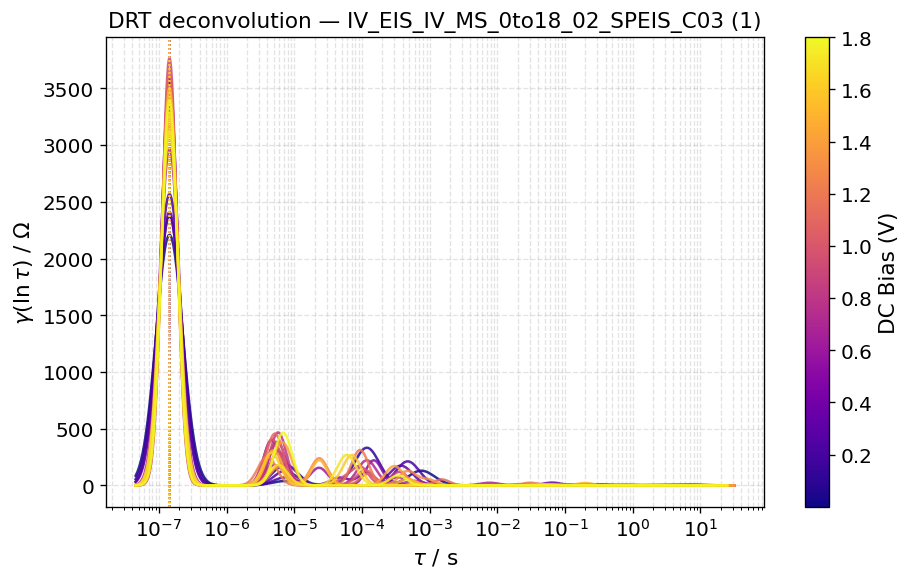

In [18]:
# ── DRT γ(τ) — all SPEIS spectra overlaid, coloured by DC bias ───────────────
if not any(sp.get("drt") is not None for sp in clean_spectra.values()):
    print("No DRT results to plot — run the DRT fit cell first.")
else:
    v_vals_drt = [sp["voltage"] for sp in clean_spectra.values()
                  if sp.get("drt") is not None]
    norm_drt = (plt.Normalize(min(v_vals_drt), max(v_vals_drt))
                if min(v_vals_drt) != max(v_vals_drt)
                else plt.Normalize(min(v_vals_drt) - 1, max(v_vals_drt) + 1))
    cmap_drt = plt.cm.plasma

    fig_drt, ax_drt = plt.subplots(figsize=(8, 5))

    for cyc, sp in clean_spectra.items():
        if sp.get("drt") is None:
            continue
        entry  = sp["drt"]
        color  = (cmap_drt(norm_drt(sp["voltage"]))
                  if np.isfinite(sp["voltage"]) else "steelblue")

        ax_drt.semilogx(entry.out_tau_vec, entry.gamma,
                        lw=1.5, color=color, alpha=0.85)

        # Mark detected peaks with vertical dotted lines
        for p in sp.get("drt_peaks", []):
            ax_drt.axvline(p["tau"], color=color, ls=":", lw=0.9, alpha=0.6)

    sm_drt = plt.cm.ScalarMappable(cmap=cmap_drt, norm=norm_drt)
    sm_drt.set_array([])
    fig_drt.colorbar(sm_drt, ax=ax_drt, label="DC Bias (V)")

    ax_drt.set_xlabel(r"$\tau$ / s", fontsize=13)
    ax_drt.set_ylabel(r"$\gamma(\ln\tau)$ / Ω", fontsize=13)
    ax_drt.set_title(f"DRT deconvolution — {Path(FILE_PATH).stem}", fontsize=13)
    ax_drt.grid(True, which="both", linestyle="--", alpha=0.35)
    plt.tight_layout()

    plt.savefig("drt_spectra.png")
    plt.show()


In [20]:
# ── DRT → ECM initial-guess suggestions ──────────────────────────────────────
# Prints a per-voltage table and a copy-pasteable block for the config cell.
# After pasting, re-run from the config cell downward (no need to re-run DRT).

if not any(sp.get("drt") is not None for sp in clean_spectra.values()):
    print("No DRT results found — run the DRT fit cell first.")
else:
    rows_drt = []
    for cyc, sp in clean_spectra.items():
        if sp.get("drt") is None:
            continue
        entry  = sp["drt"]
        peaks  = sp.get("drt_peaks", [])
        v      = sp["voltage"]
        # R∞: pyDRTtools stores it in entry.R; fall back to highest-freq Re(Z)
        R_inf  = float(getattr(entry, "R",
                               entry.mu_Z_re[int(np.argmax(entry.freq))]))
        row = {"Voltage (V)": round(float(v), 4), "R0_inf [Ω]": round(R_inf, 3)}
        for i, p in enumerate(peaks):
            row[f"R{i+1} [Ω]"]    = round(p["R"],   3)
            row[f"τ{i+1} [s]"]    = f"{p['tau']:.3e}"
            row[f"Q{i+1} [S·sᵅ]"] = f"{p['Q']:.3e}"
        rows_drt.append(row)

    df_drt_summary = pd.DataFrame(rows_drt)
    print("DRT-derived parameters per voltage step:\n")
    print(df_drt_summary.to_string(index=False))

    # ── Reference spectrum: closest to 0 V (largest arc, most stable fit) ────
    fitted_ok = [sp for sp in clean_spectra.values()
                 if sp.get("drt") is not None and sp.get("drt_peaks")]
    if fitted_ok:
        ref       = min(fitted_ok, key=lambda sp: abs(sp["voltage"]))
        ref_entry = ref["drt"]
        ref_peaks = ref["drt_peaks"]
        n_peaks   = len(ref_peaks)
        R0_ref    = float(getattr(ref_entry, "R",
                                  ref_entry.mu_Z_re[int(np.argmax(ref_entry.freq))]))

        print(f"\n{'═'*64}")
        print(f"  Suggested N_RC = {n_peaks}  "
              f"({n_peaks} DRT peak(s) found at reference {ref['voltage']:+.4f} V)")
        print(f"{'═'*64}")
        print("\n  ── Copy this block into the USER CONFIGURATION cell ──\n")
        print(f"  N_RC = {n_peaks}")
        print(f"  INITIAL_GUESS_ALL = [")
        print(f"      {R0_ref:.4g},   # R0  — series resistance [Ω]  (DRT R∞)")
        for i, p in enumerate(ref_peaks):
            print(f"      {p['R']:.4g},   # R{i+1}  — arc {i+1} resistance [Ω]  (DRT peak area)")
            print(f"      {p['Q']:.3e},   # CPE{i+1}_0  Q [S·sᵅ]  (Q = τ^α / R, α={DRT_ALPHA_ASSUMED})")
            print(f"      0.85,   # CPE{i+1}_1  α  — adjust if DRT peak is asymmetric")
        print(f"  ]")

        # R range across voltages
        print(f"\n  ── Parameter ranges across all {len(rows_drt)} voltage steps ──")
        r0_vals = [r["R0_inf [Ω]"] for r in rows_drt]
        print(f"  R0  : {min(r0_vals):.3g} – {max(r0_vals):.3g} Ω")
        for i in range(n_peaks):
            key = f"R{i+1} [Ω]"
            rv  = [r[key] for r in rows_drt if key in r]
            if rv:
                print(f"  R{i+1}  : {min(rv):.3g} – {max(rv):.3g} Ω")


DRT-derived parameters per voltage step:

 Voltage (V)  R0_inf [Ω]   R1 [Ω]    τ1 [s] Q1 [S·sᵅ]
      0.0002    3826.827 2431.213 1.451e-07 6.334e-10
      0.1001    3950.320 2438.124 1.421e-07 6.203e-10
      0.2001    4039.036 2475.946 1.466e-07 6.271e-10
      0.3001    4065.490 2284.374 1.442e-07 6.704e-10
      0.4001    3780.077 2419.623 1.430e-07 6.286e-10
      0.5001    3827.395 2355.868 1.442e-07 6.502e-10
      0.6001    3681.862 2485.218 1.410e-07 6.045e-10
      0.7001    3822.939 2387.214 1.440e-07 6.407e-10
      0.8001    3913.355 2277.131 1.450e-07 6.756e-10
      0.9000    3820.644 2340.993 1.408e-07 6.412e-10
      1.0000    3786.388 2365.327 1.450e-07 6.504e-10
      1.1001    3782.972 2358.205 1.414e-07 6.387e-10
      1.2001    3782.888 2330.661 1.404e-07 6.422e-10
      1.3000    3747.738 2392.272 1.427e-07 6.345e-10
      1.4001    3768.748 2331.903 1.410e-07 6.443e-10
      1.5000    3846.752 2276.844 1.423e-07 6.652e-10
      1.6000    3827.199 2291.466 1.438e

---
## 6 — Configuration

**Edit this cell** to match your measurement.

### Parameter ordering rules
`impedance.py` reads parameters **left-to-right** through the circuit string.  
For `R0-p(R1,CPE1)-p(R2,CPE2)` the full order is:

| Index | Name    | Description                      | Typical range         |
|-------|---------|----------------------------------|-----------------------|
| 0     | `R0`    | Series / contact resistance      | 1 – 1 000 Ω           |
| 1     | `R1`    | Arc 1 resistance                 | 10 – 1 × 10⁶ Ω        |
| 2     | `CPE1_0`| Arc 1 CPE prefactor Q            | 1×10⁻¹⁰ – 1×10⁻³      |
| 3     | `CPE1_1`| Arc 1 CPE exponent α             | 0.5 – 1.0             |
| 4     | `R2`    | Arc 2 resistance                 | 10 – 1 × 10⁶ Ω        |
| 5     | `CPE2_0`| Arc 2 CPE prefactor Q            | 1×10⁻¹⁰ – 1×10⁻³      |
| 6     | `CPE2_1`| Arc 2 CPE exponent α             | 0.5 – 1.0             |

> **Freezing parameters**: add an entry to `FROZEN_PARAMS`, e.g. `{"R0": 10.0}`.  
> The `INITIAL_GUESS` and bounds arrays below cover **all** parameters for reference,  
> but only the **free** ones (those not in `FROZEN_PARAMS`) are passed to the fitter.

In [23]:
# ═══════════════════════════════════════════════════════════════════
#  USER CONFIGURATION — edit values in this cell
# ═══════════════════════════════════════════════════════════════════

# ── Circuit topology ─────────────────────────────────────────────────────────
N_RC = 1   # number of RC arcs: 1, 2, or 3

_arcs = "-".join(f"p(R{i},CPE{i})" for i in range(1, N_RC + 1))
CIRCUIT_STRING = f"R0-{_arcs}"
print(f"Circuit: {CIRCUIT_STRING}")

# ── SPEIS: which voltage steps to fit ────────────────────────────────────────
# "all"   → fit every cycle found in the file
# [1,3,5] → fit only those cycle numbers (e.g. [2, 4, 6, 8, 10, 12])
CYCLES_TO_FIT = "all"

# ── Frequency window (Hz) — set None to keep all data ────────────────────────
F_MIN = None    # e.g. 1e-2
F_MAX = None    # e.g. 1e6

# ── Parameters to freeze (held constant during fit) ──────────────────────────
# Leave empty {} to fit all parameters freely.
# Example: FROZEN_PARAMS = {"R0": 10.0}  freezes series resistance at 10 Ω
FROZEN_PARAMS: dict[str, float] = {}

# ── Initial guesses (ALL parameters, in circuit order) ───────────────────────
# 1-arc order: R0, R1, CPE1_0, CPE1_1
# 2-arc order: R0, R1, CPE1_0, CPE1_1, R2, CPE2_0, CPE2_1
# 3-arc order: add R3, CPE3_0, CPE3_1
if N_RC == 1:
    INITIAL_GUESS_ALL = [
      3827,   # R0  — series resistance [Ω]  (DRT R∞)
      2431,   # R1  — arc 1 resistance [Ω]  (DRT peak area)
      6.334e-10,   # CPE1_0  Q [S·sᵅ]  (Q = τ^α / R, α=0.85)
      0.85,   # CPE1_1  α  — adjust if DRT peak is asymmetric
  ]
elif N_RC == 2:
    INITIAL_GUESS_ALL = [
        50.0,      # R0   — series resistance [Ω]
        15000.0,   # R1   — arc 1 resistance  [Ω]
        1e-8,      # CPE1_0  Q [S·sᵅ]
        0.85,      # CPE1_1  α (0.5–1.0)
        5000.0,    # R2   — arc 2 resistance  [Ω]
        1e-9,      # CPE2_0  Q [S·sᵅ]
        0.80,      # CPE2_1  α (0.5–1.0)
    ]
elif N_RC == 3:
    INITIAL_GUESS_ALL = [
        50.0,    15000.0, 1e-8,  0.85,
        5000.0,  1e-9,    0.80,
        2000.0,  1e-10,   0.75,
    ]
else:
    raise ValueError("N_RC must be 1, 2, or 3")

# ── Bounds (ALL parameters, same order as INITIAL_GUESS_ALL) ─────────────────
# Strict CPE alpha limits: 0.5 ≤ α ≤ 1.0
# R0 upper bound capped at 500 Ω — arc clearly starts near origin
if N_RC == 1:
    LOWER_BOUNDS_ALL = [0.0,  0.0,  1e-12, 0.5]
    UPPER_BOUNDS_ALL = [5000.0, 5e5,  1e-3,  1.0]
elif N_RC == 2:
    LOWER_BOUNDS_ALL = [0.0,  0.0,  1e-12, 0.5,  0.0,  1e-12, 0.5]
    UPPER_BOUNDS_ALL = [500.0, 5e5,  1e-3,  1.0,  5e5,  1e-3,  1.0]
elif N_RC == 3:
    LOWER_BOUNDS_ALL = [0.0,  0.0,  1e-12, 0.5,  0.0,  1e-12, 0.5,  0.0,  1e-12, 0.5]
    UPPER_BOUNDS_ALL = [500.0, 5e5,  1e-3,  1.0,  5e5,  1e-3,  1.0,  5e5,  1e-3,  1.0]


Circuit: R0-p(R1,CPE1)


---
## 7 — Equivalent Circuit Fitting

### What happens here
1. The parameter names are queried with `get_param_names()` to confirm the ordering.
2. Any parameters listed in `FROZEN_PARAMS` are removed from `initial_guess` and `bounds` — only **free** parameters are passed to `CustomCircuit`.
3. `circuit.fit()` is called with:
   - `bounds` — enforces physical constraints (CPE α strictly in [0.5, 1.0])
   - `weight_by_modulus=True` — uses |Z| as weights, the standard approach when experimental variances are unknown
4. Fit parameters and their 1σ errors are printed.

In [24]:
# ── Build a temporary circuit (no constants) to get the parameter name list ──
_tmp = CustomCircuit(CIRCUIT_STRING, initial_guess=INITIAL_GUESS_ALL)
all_param_names, all_param_units = _tmp.get_param_names()

print("All parameters in circuit order:")
for name, unit, val, lo, hi in zip(
    all_param_names, all_param_units,
    INITIAL_GUESS_ALL, LOWER_BOUNDS_ALL, UPPER_BOUNDS_ALL,
):
    frozen_tag = f"  ← FROZEN at {FROZEN_PARAMS[name]}" if name in FROZEN_PARAMS else ""
    print(f"  {name:10s}  [{unit}]   init={val:.2e}   bounds=[{lo:.1e}, {hi:.1e}]{frozen_tag}")

# ── Filter to free parameters only ────────────────────────────────────────────
free_names   = [n for n in all_param_names if n not in FROZEN_PARAMS]
free_indices = [i for i, n in enumerate(all_param_names) if n not in FROZEN_PARAMS]

initial_guess_free = [INITIAL_GUESS_ALL[i] for i in free_indices]
lower_bounds_free  = [LOWER_BOUNDS_ALL[i]  for i in free_indices]
upper_bounds_free  = [UPPER_BOUNDS_ALL[i]  for i in free_indices]

assert len(initial_guess_free) == len(lower_bounds_free) == len(upper_bounds_free), \
    "Mismatch between initial_guess and bounds lengths — check N_RC."

print(f"\nFree parameters ({len(free_names)}): {free_names}")
print(f"Frozen parameters: {list(FROZEN_PARAMS.keys())}")

All parameters in circuit order:
  R0          [Ohm]   init=3.83e+03   bounds=[0.0e+00, 5.0e+03]
  R1          [Ohm]   init=2.43e+03   bounds=[0.0e+00, 5.0e+05]
  CPE1_0      [Ohm^-1 sec^a]   init=6.33e-10   bounds=[1.0e-12, 1.0e-03]
  CPE1_1      []   init=8.50e-01   bounds=[5.0e-01, 1.0e+00]

Free parameters (4): ['R0', 'R1', 'CPE1_0', 'CPE1_1']
Frozen parameters: []


In [25]:
for cyc, sp in clean_spectra.items():
    frequencies_clean = sp["freq"]
    Z_clean = sp["Z"]

    print(f"\nCycle {cyc:.0f}: {Path(FILE_PATH).stem}, Voltage of: {sp['voltage']:.3f} V")


    # ── Instantiate and fit ───────────────────────────────────────────────────────
    circuit = CustomCircuit(
        CIRCUIT_STRING,
        initial_guess=initial_guess_free,
        constants=FROZEN_PARAMS,
    )

    circuit.fit(
        frequencies_clean,
        Z_clean,
        bounds=(lower_bounds_free, upper_bounds_free),
        weight_by_modulus=True,
    )

    # ── Print fitted parameters ───────────────────────────────────────────────────
    param_names_fit, param_units_fit = circuit.get_param_names()
    params = circuit.parameters_
    errors = circuit.conf_

    print("\n" + "═" * 58)
    print(f"  Fitted circuit: {CIRCUIT_STRING}")
    print("═" * 58)
    print(f"  {'Parameter':<12} {'Value':>14}  {'±1σ':>14}  Unit")
    print("  " + "-" * 54)
    for name, unit, val, err in zip(param_names_fit, param_units_fit, params, errors):
        print(f"  {name:<12} {val:>14.4e}  {err:>14.4e}  {unit}")
    print("═" * 58)

    clean_spectra[cyc]['circuit'] = circuit

    # Relative error check (>50 % → poor convergence warning)
    for name, val, err in zip(param_names_fit, params, errors):
        if err / abs(val) > 0.5:
            print(f"  ⚠  {name}: large relative error ({err/abs(val)*100:.0f} %) — "
                  "consider tightening bounds or adjusting initial guess.")


Cycle 1: IV_EIS_IV_MS_0to18_02_SPEIS_C03 (1), Voltage of: 0.000 V

══════════════════════════════════════════════════════════
  Fitted circuit: R0-p(R1,CPE1)
══════════════════════════════════════════════════════════
  Parameter             Value             ±1σ  Unit
  ------------------------------------------------------
  R0               3.8270e+03      6.2547e+02  Ohm
  R1               2.4310e+03      8.5469e+02  Ohm
  CPE1_0           6.3340e-10      8.1993e-09  Ohm^-1 sec^a
  CPE1_1           8.5000e-01      7.2646e-02  
══════════════════════════════════════════════════════════
  ⚠  CPE1_0: large relative error (1294 %) — consider tightening bounds or adjusting initial guess.

Cycle 2: IV_EIS_IV_MS_0to18_02_SPEIS_C03 (1), Voltage of: 0.100 V

══════════════════════════════════════════════════════════
  Fitted circuit: R0-p(R1,CPE1)
══════════════════════════════════════════════════════════
  Parameter             Value             ±1σ  Unit
  --------------------------------

---
## 8 — Visualization

### 8a — Nyquist plot with fit residuals

The figure has two panels:
- **Top (Nyquist):** experimental data as filled circles, fitted model as a solid line. The frequencies are annotated on a subset of points (decade steps).
- **Bottom (Residuals):** normalised residuals in % for the real and imaginary parts vs log-frequency. A good fit stays within ±5 %.

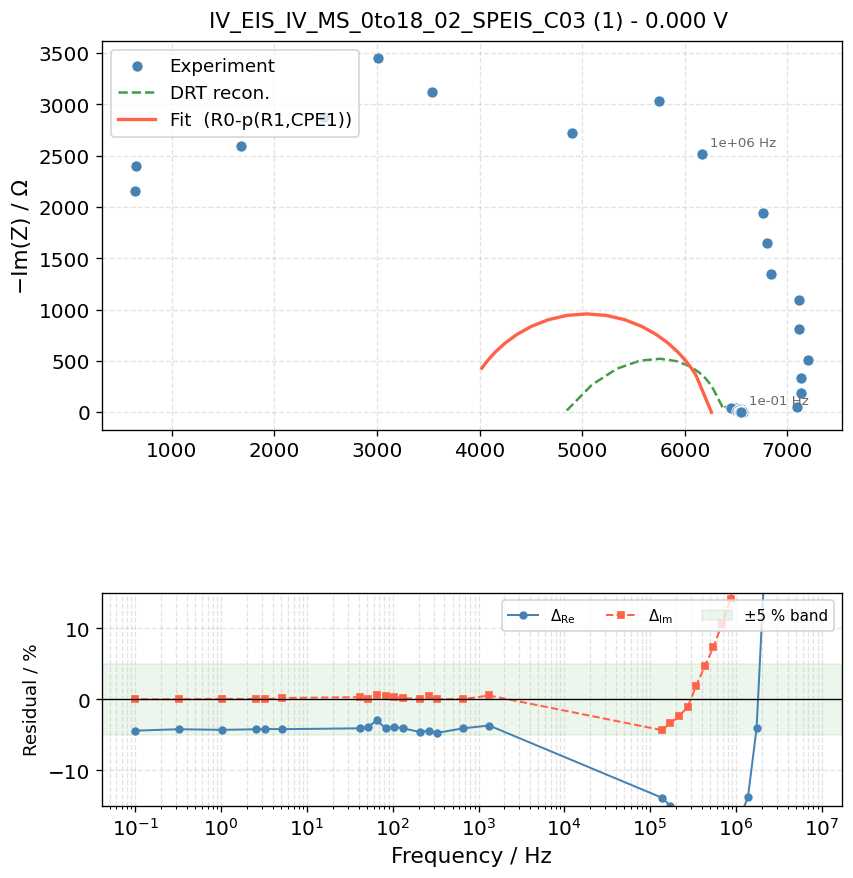

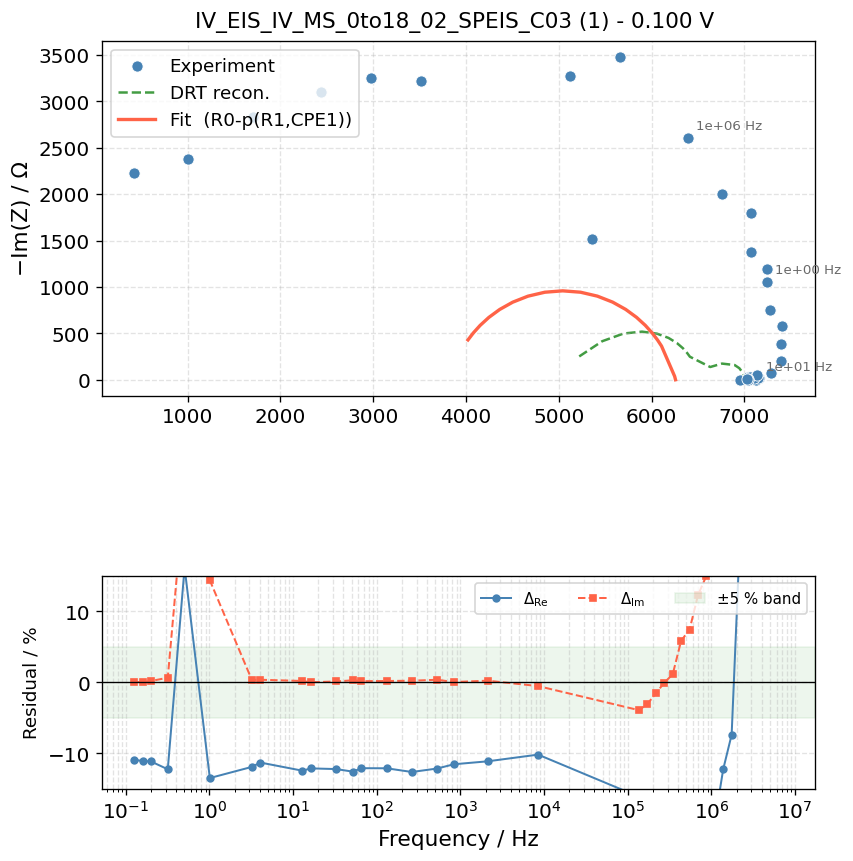

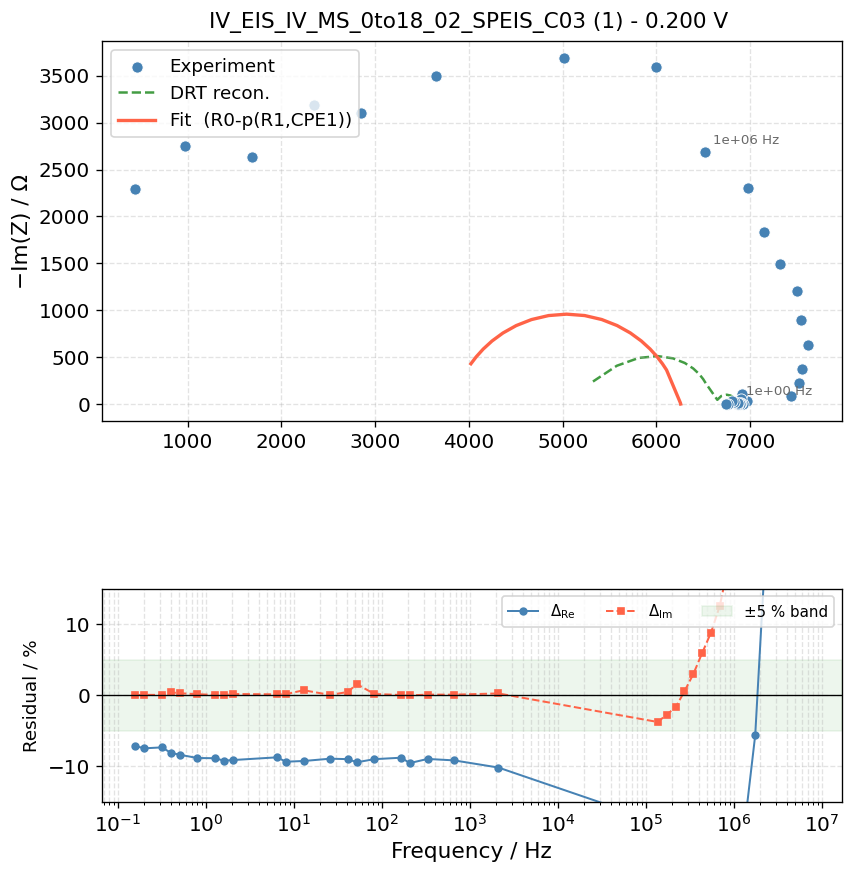

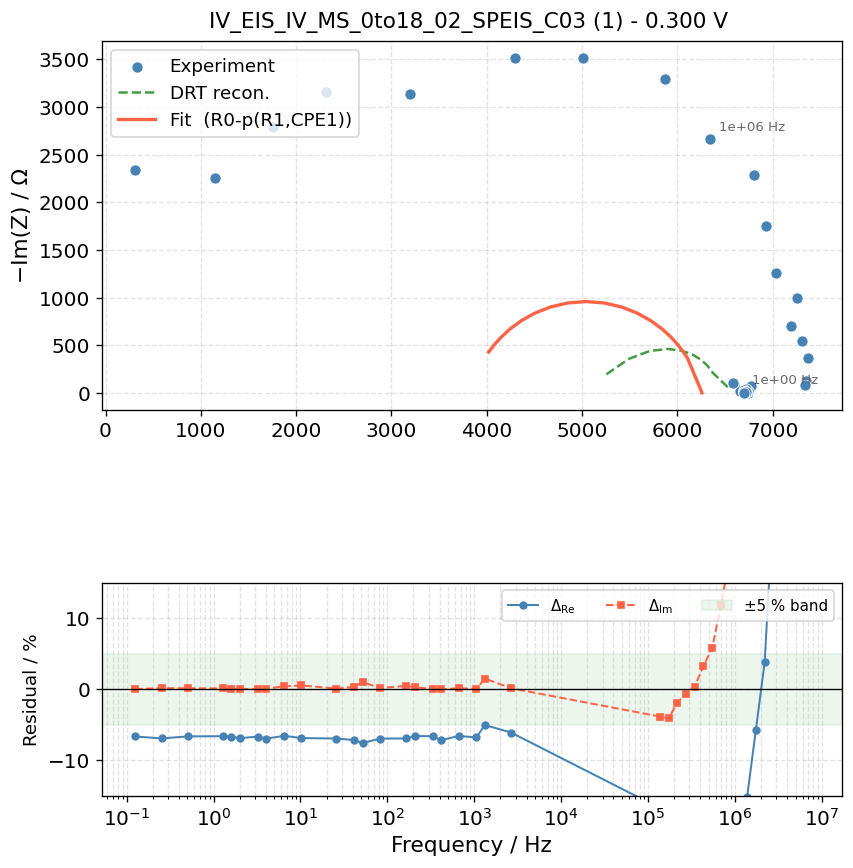

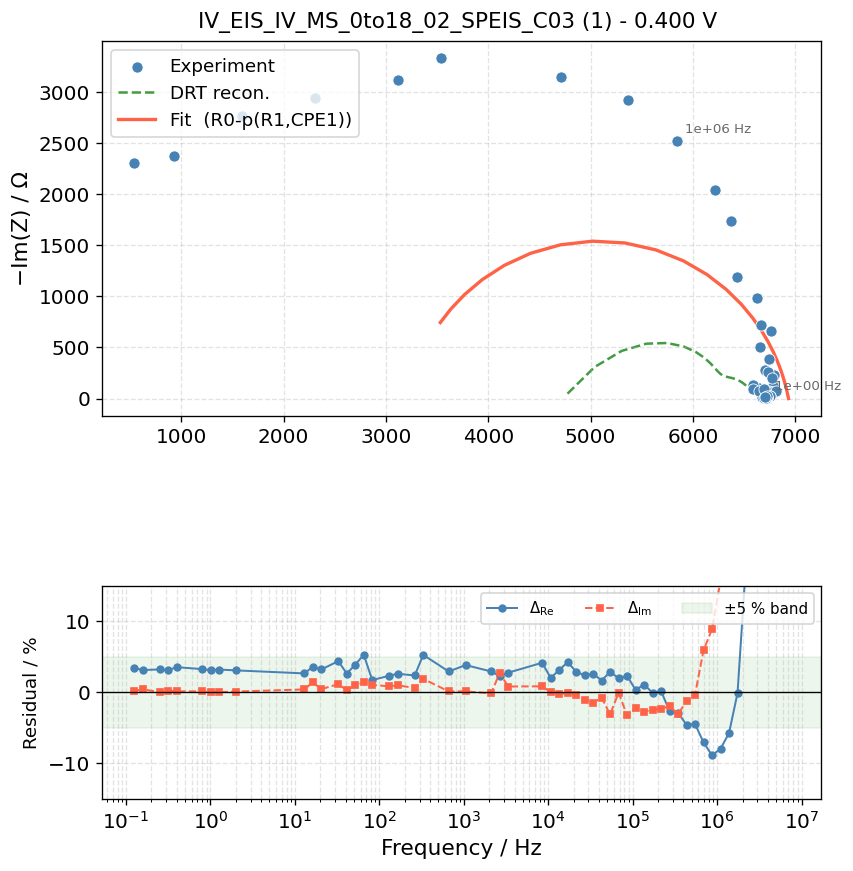

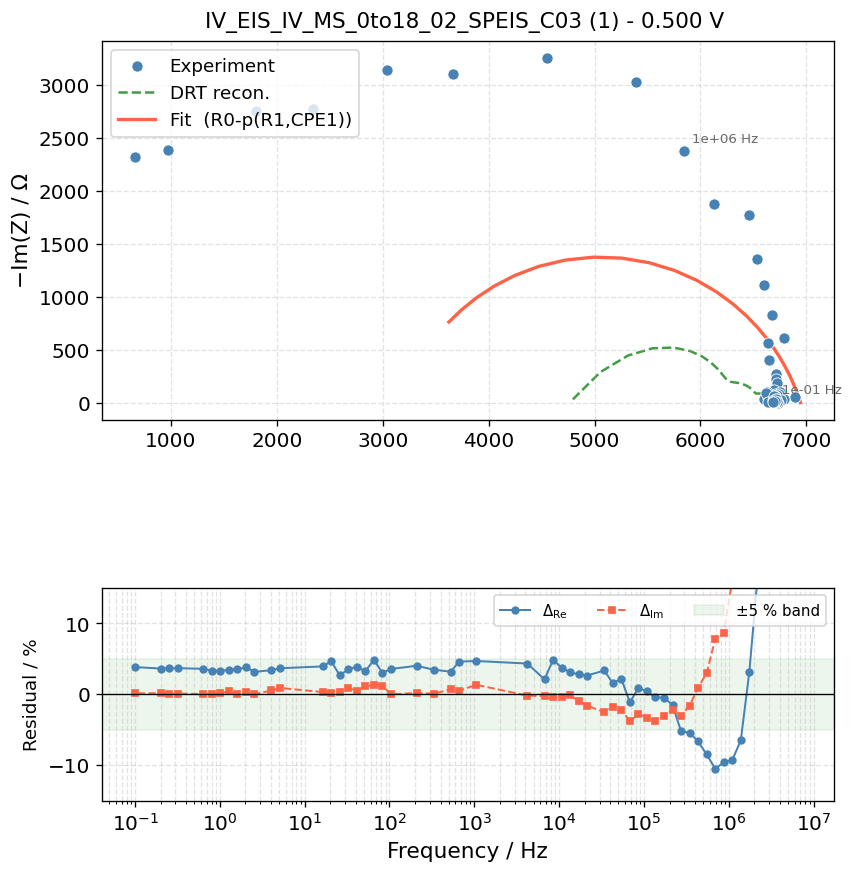

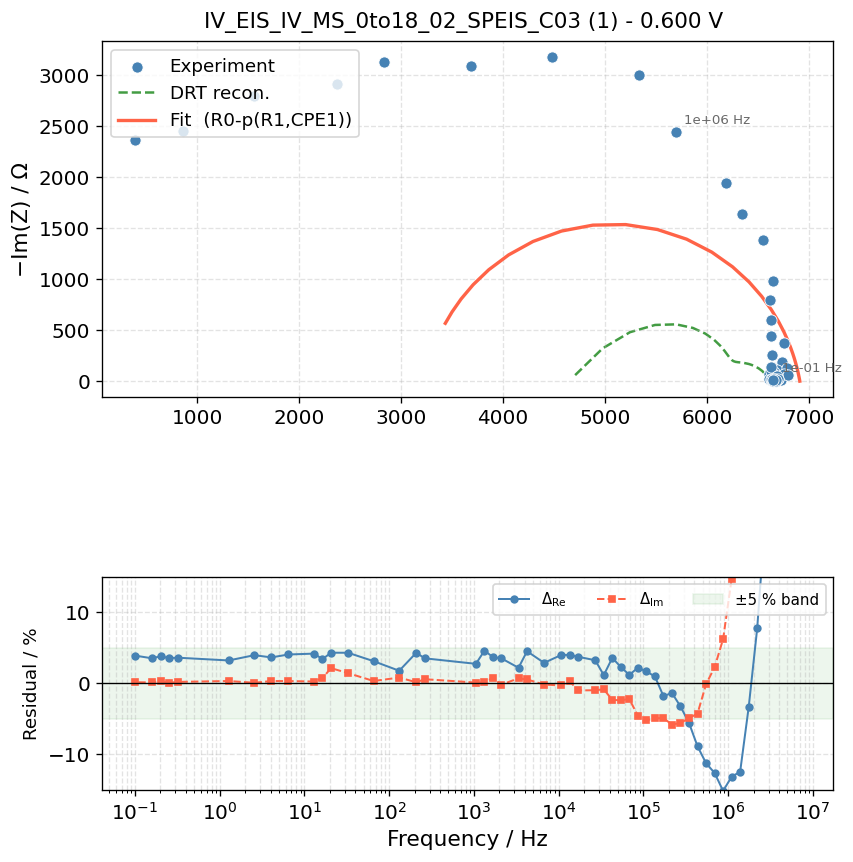

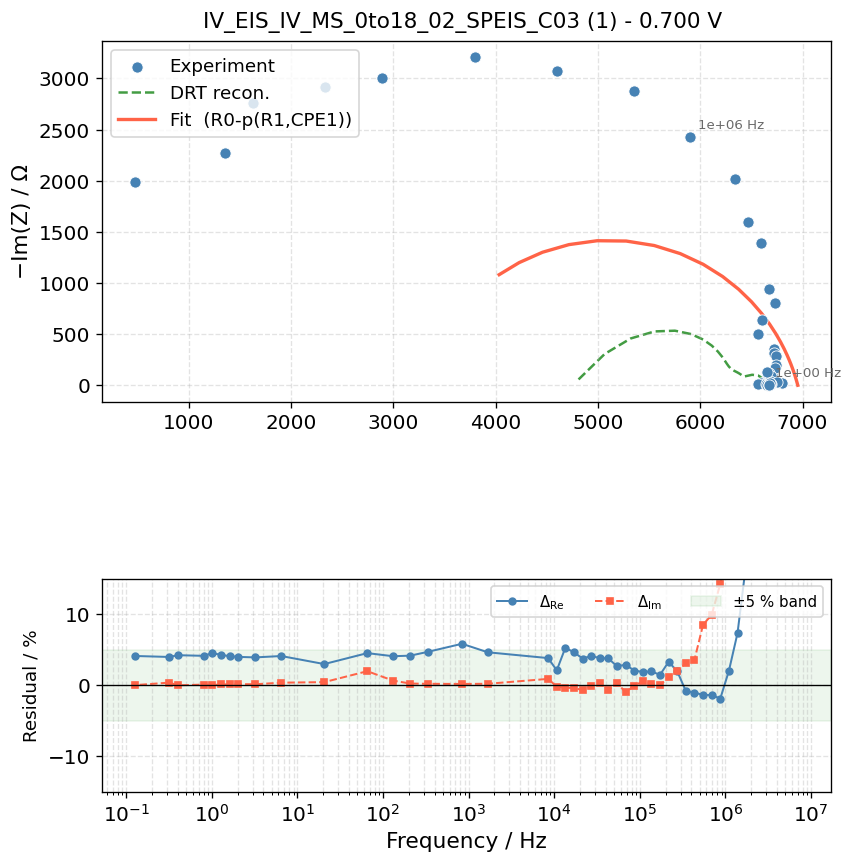

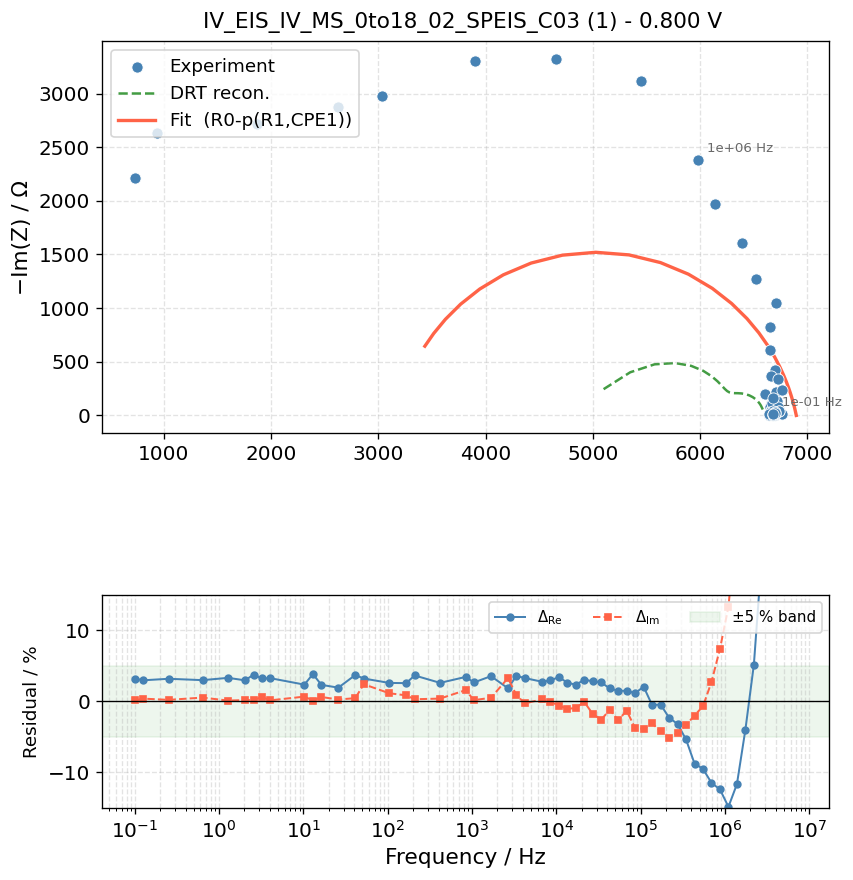

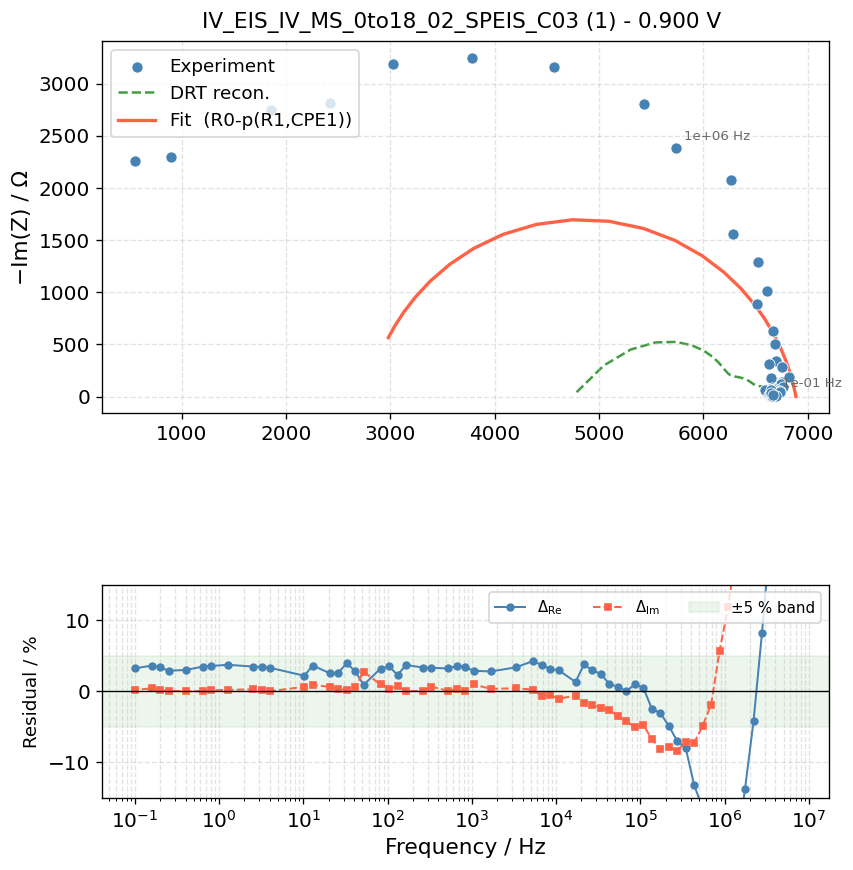

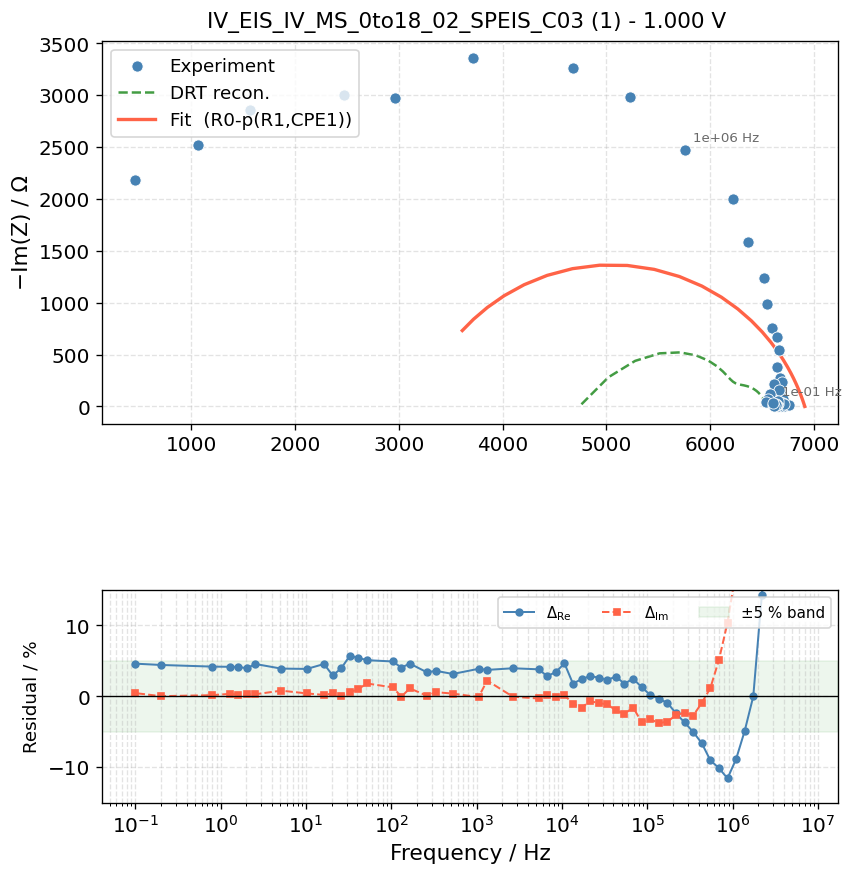

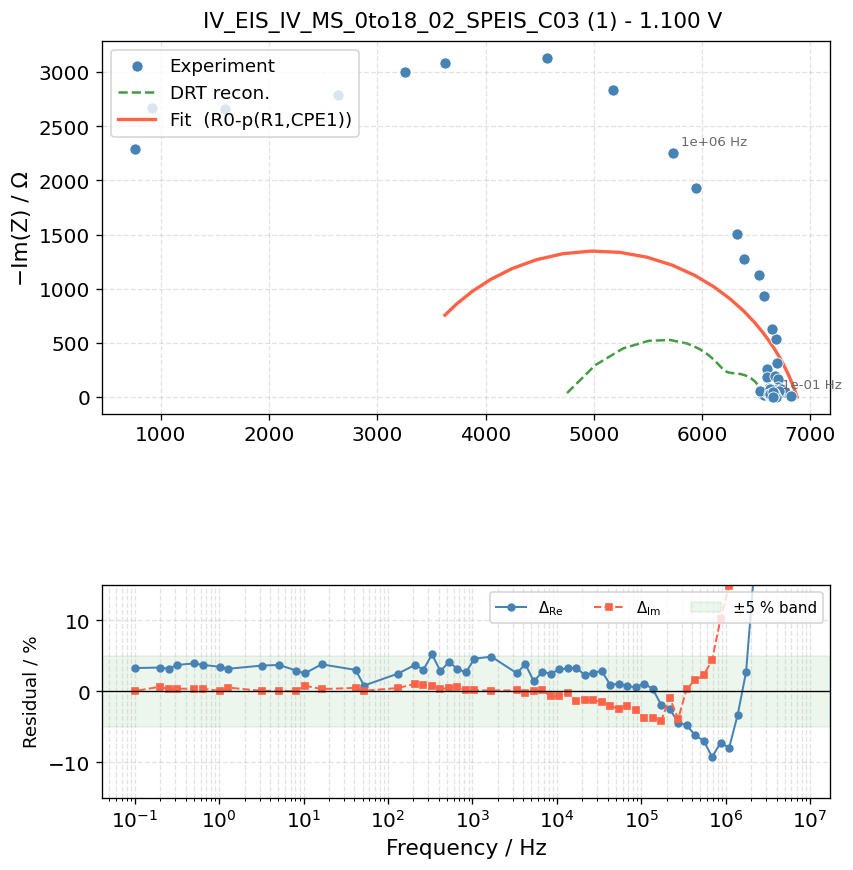

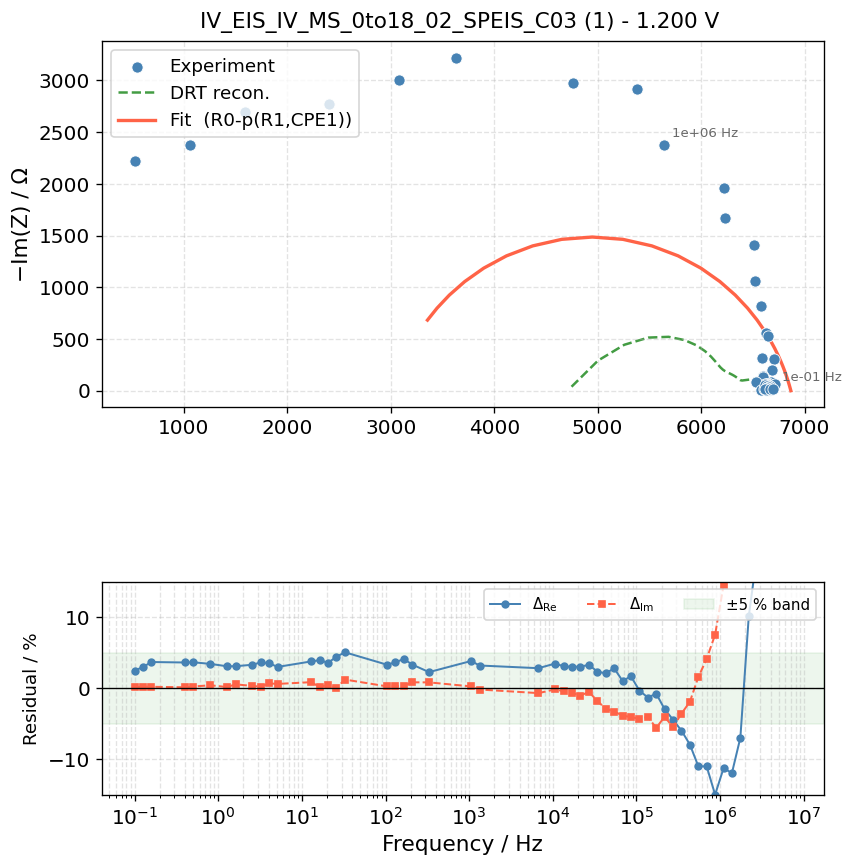

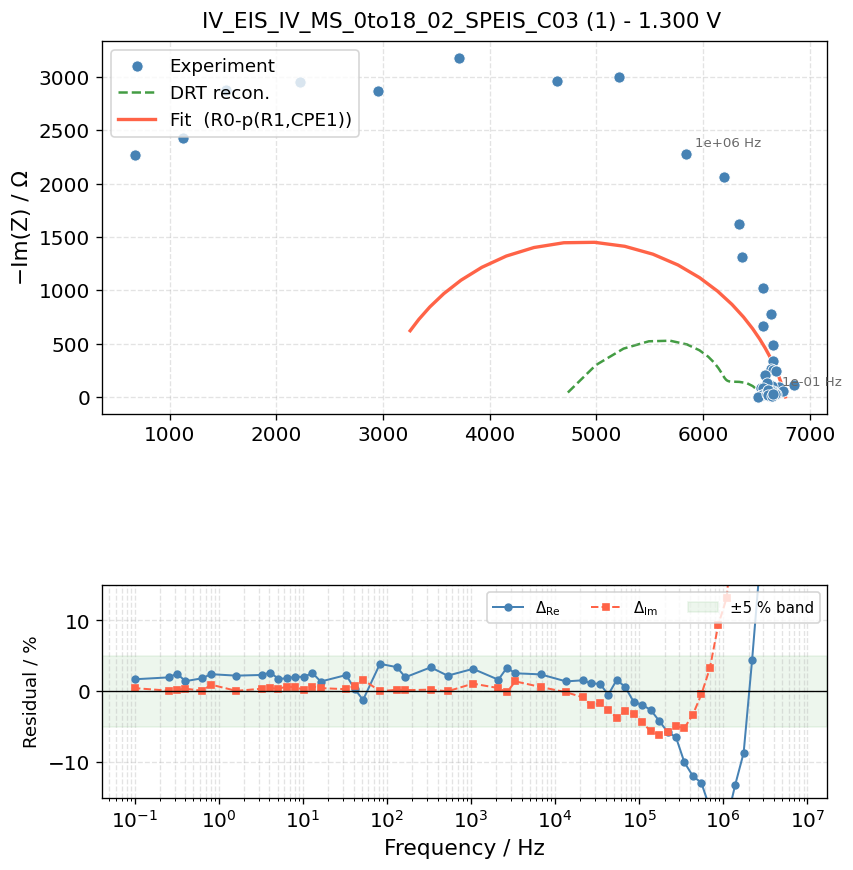

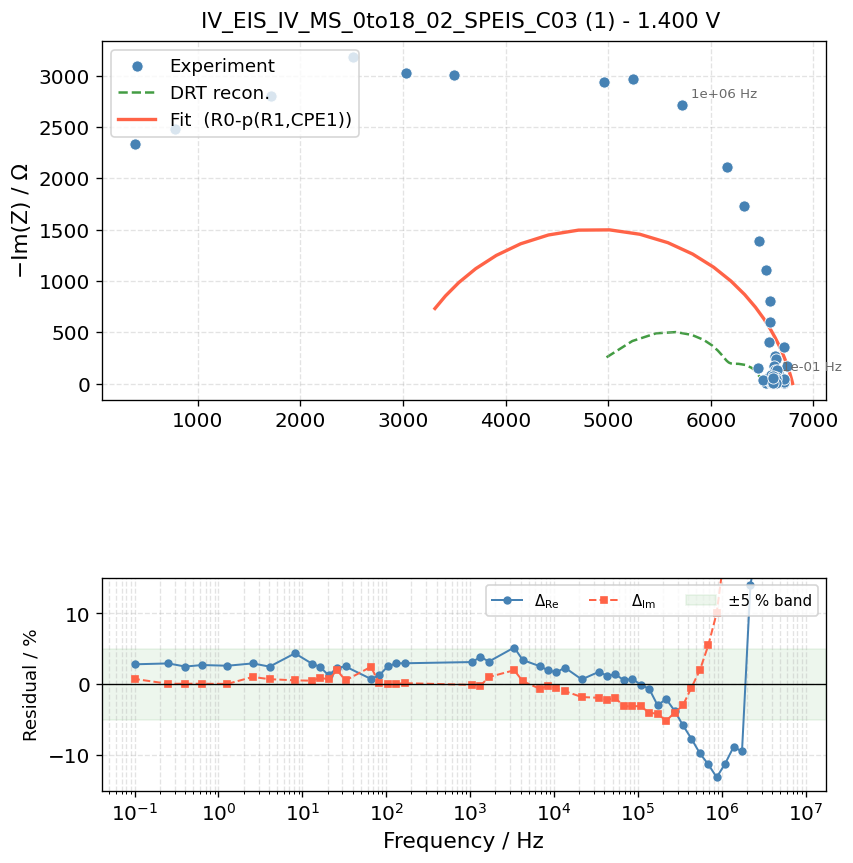

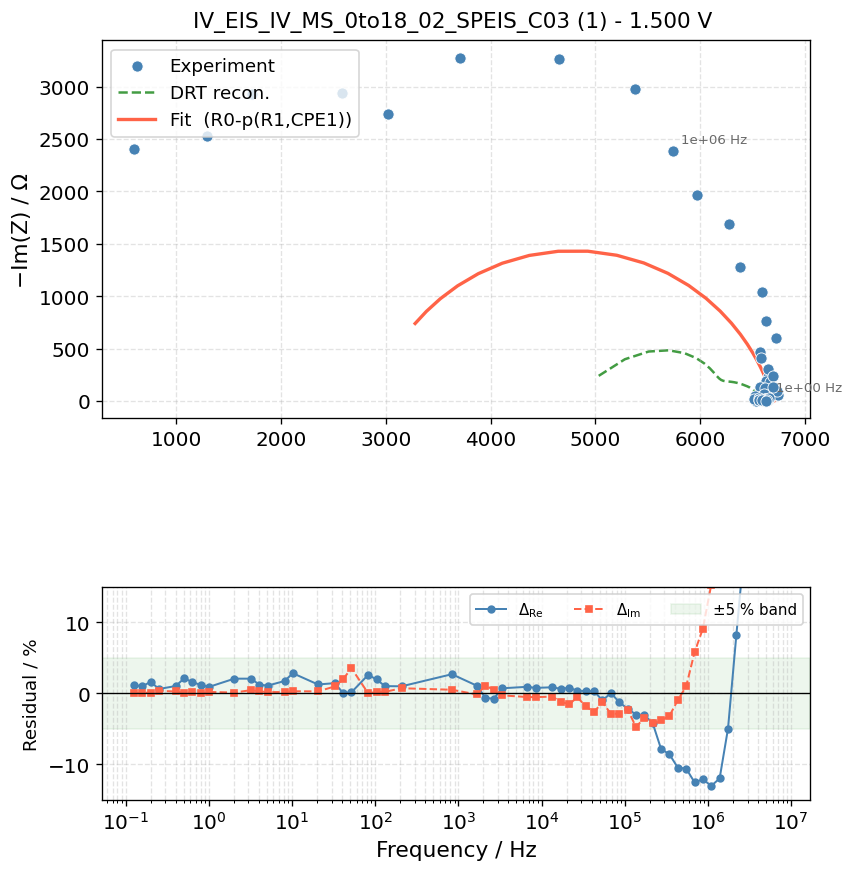

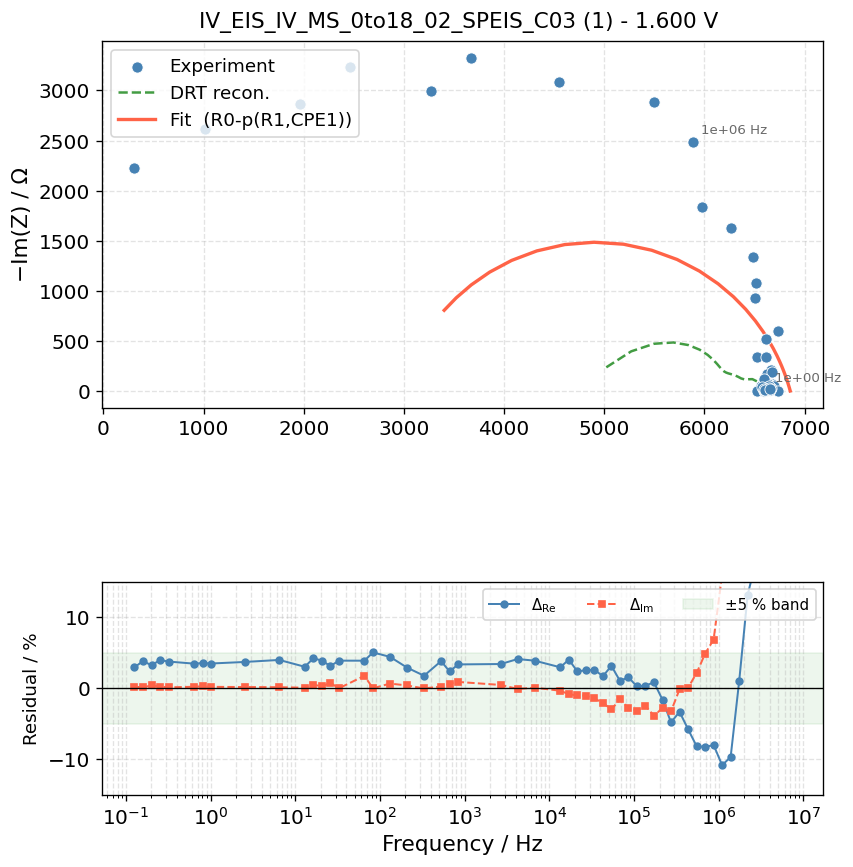

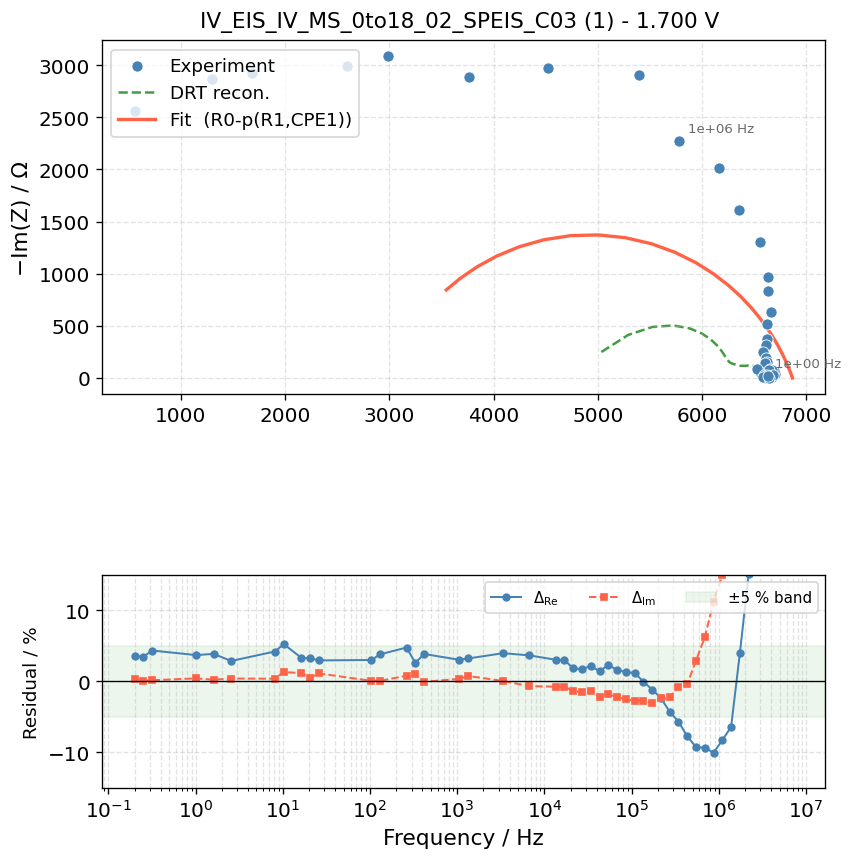

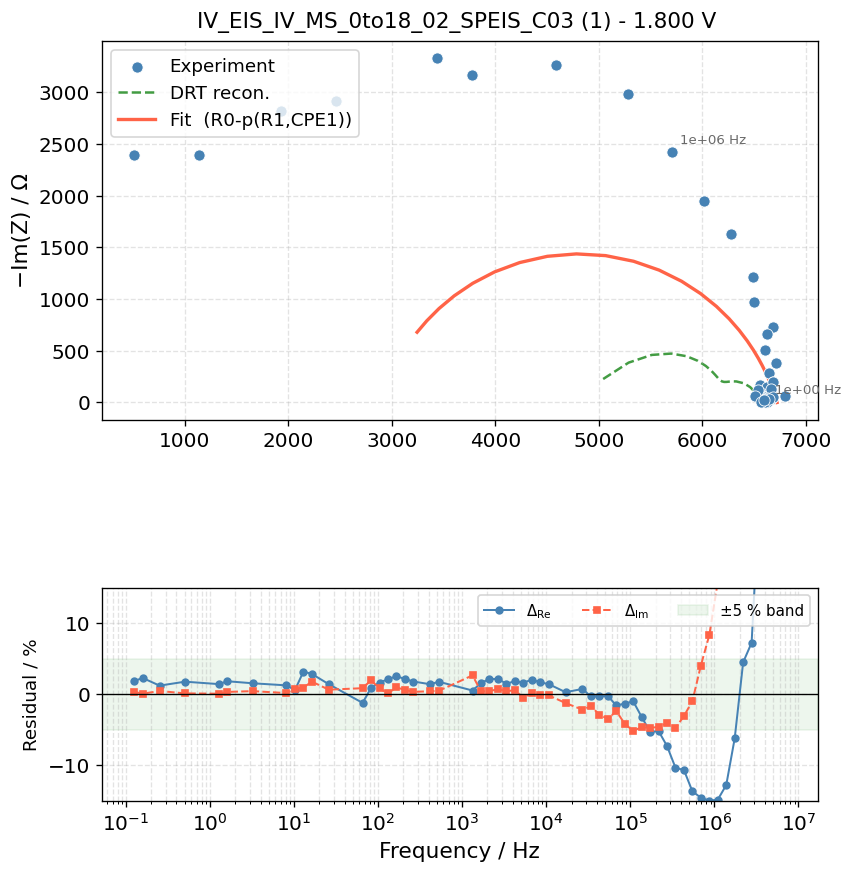

In [28]:
def plot_nyquist_with_residuals(
    freq: np.ndarray,
    Z_data: np.ndarray,
    Z_fit: np.ndarray,
    Z_drt: "np.ndarray | None" = None,
    title: str = "",
    save_path: str | None = None,
) -> None:
    """Publication-quality Nyquist plot with normalised residual panel.

    Parameters
    ----------
    freq     : frequency array (Hz)
    Z_data   : experimental complex impedance  (impedance.py convention: Im < 0)
    Z_fit    : ECM fitted complex impedance    (same convention, same length)
    Z_drt    : DRT reconstructed impedance     (optional; same convention/length)
    title    : optional axes title
    save_path: if given, save figure to this path (e.g. "nyquist.pdf")
    """
    # Normalised residuals for the ECM fit (%)
    norm = np.abs(Z_data)
    res_re = (Z_fit.real - Z_data.real) / norm * 100
    res_im = (Z_fit.imag - Z_data.imag) / norm * 100

    fig = plt.figure(figsize=(7, 8), constrained_layout=True)
    gs = gridspec.GridSpec(2, 1, height_ratios=[3, 1], figure=fig, hspace=0.08)

    # ── Top: Nyquist ─────────────────────────────────────────────────────────
    ax_ny = fig.add_subplot(gs[0])
    ax_ny.scatter(
        Z_data.real, -Z_data.imag,
        s=45, zorder=3, color="steelblue", edgecolors="white", linewidths=0.5,
        label="Experiment",
    )
    # DRT reconstruction (drawn first so ECM fit sits on top)
    if Z_drt is not None:
        ax_ny.plot(
            Z_drt.real[Z_drt.imag>0], Z_drt.imag[Z_drt.imag>0],
            lw=1.5, color="forestgreen", ls="--", zorder=1, alpha=0.85,
            label="DRT recon.",
        )
    ax_ny.plot(
        Z_fit.real[-Z_fit.imag>0], -Z_fit.imag[-Z_fit.imag>0],
        lw=2, color="tomato", zorder=2, label=f"Fit  ({CIRCUIT_STRING})",
    )

    # Annotate decade frequency markers
    log_f = np.log10(freq)
    decade_targets = np.arange(np.ceil(log_f.min()), np.floor(log_f.max()) + 1)
    x_range = Z_data.real.max() - Z_data.real.min()
    min_spacing = x_range * 0.12
    last_xy = (-np.inf, -np.inf)
    for target in decade_targets:
        idx = np.argmin(np.abs(log_f - target))
        xy = (Z_data.real[idx], -Z_data.imag[idx])
        dist = np.hypot(xy[0] - last_xy[0], xy[1] - last_xy[1])
        if dist < min_spacing:
            continue
        ax_ny.annotate(
            f"{10**target:.0e} Hz",
            xy=xy,
            xytext=(5, 5), textcoords="offset points",
            fontsize=8, color="dimgray",
        )
        last_xy = xy

    ax_ny.set_ylabel("−Im(Z) / Ω", fontsize=13)
    ax_ny.set_aspect("equal", adjustable="box")
    ax_ny.legend(fontsize=11, loc="upper left")
    ax_ny.grid(True, linestyle="--", alpha=0.35)
    if title:
        ax_ny.set_title(title, fontsize=13, pad=8)



    # ── Bottom: Residuals ─────────────────────────────────────────────────────
    ax_res = fig.add_subplot(gs[1])
    ax_res.semilogx(
        freq, res_re, "o-", ms=4, lw=1.2, color="steelblue", label=r"$\Delta_\mathrm{Re}$"
    )
    ax_res.semilogx(
        freq, res_im, "s--", ms=4, lw=1.2, color="tomato", label=r"$\Delta_\mathrm{Im}$"
    )
    ax_res.axhline(0, color="black", lw=0.8)
    ax_res.axhspan(-5, 5, alpha=0.07, color="green", label="±5 % band")
    ax_res.set_xlabel("Frequency / Hz", fontsize=13)
    ax_res.set_ylabel("Residual / %", fontsize=11)
    ax_res.legend(fontsize=9, loc="upper right", ncol=3)
    ax_res.grid(True, which="both", linestyle="--", alpha=0.35)
    ax_res.set_ylim(-15, 15)

    if save_path:
        fig.savefig(save_path, dpi=200, bbox_inches="tight")
        print(f"Saved → {save_path}")
    plt.show()


for cyc, sp in clean_spectra.items():
    frequencies_clean = sp["freq"]
    Z_clean = sp["Z"]
    circuit = sp["circuit"]

    # ── DRT reconstruction (only if DRT was run for this spectrum) ────────────
    # pyDRTtools uses Z_double_prime = -Im(Z) > 0, so mu_Z_im = -Im(Z) > 0.
    # Convert back to impedance.py convention (Im < 0) for the plot function.
    drt_entry = sp.get("drt")
    if drt_entry is not None:
        Z_drt = drt_entry.mu_Z_re - 1j * drt_entry.mu_Z_im
    else:
        Z_drt = None

    # ── ECM fit ───────────────────────────────────────────────────────────────
    Z_fit = circuit.predict(frequencies_clean)

    plot_nyquist_with_residuals(
        frequencies_clean,
        Z_clean,
        Z_fit,
        Z_drt=Z_drt,
        title=Path(FILE_PATH).stem + f" - {sp['voltage']:.3f} V ",
        save_path=None,      # e.g. "nyquist_fit.pdf"
    )


### 7b — Bode plot

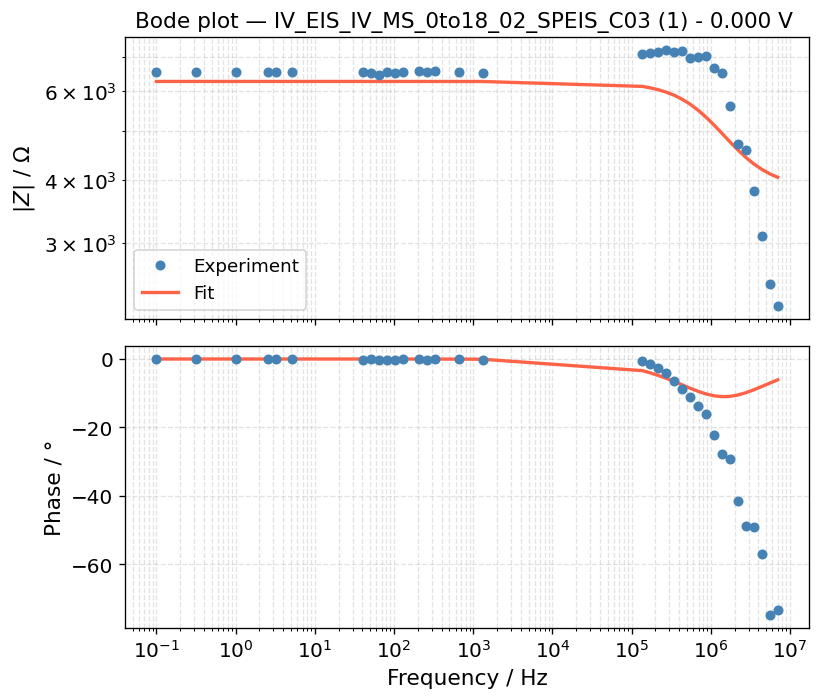

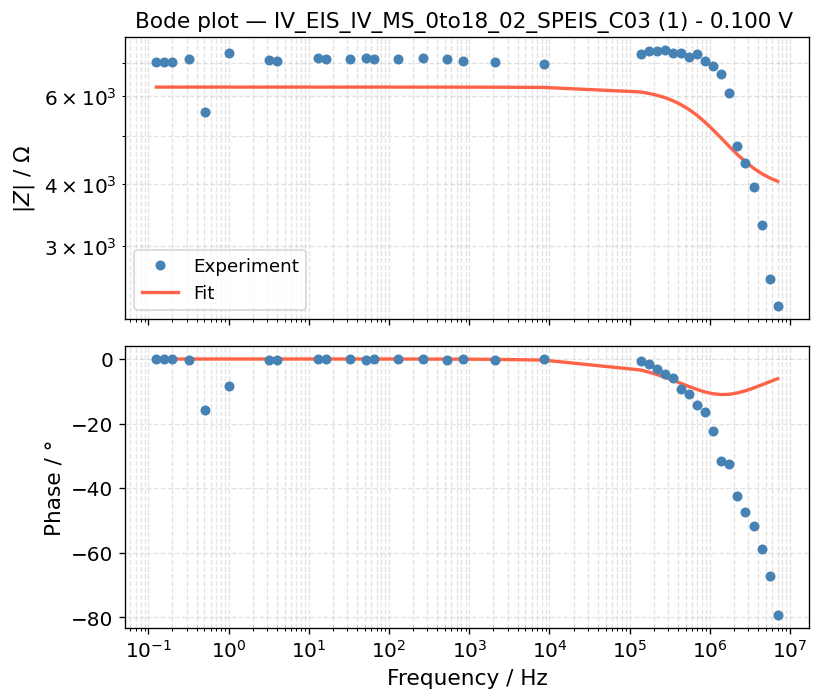

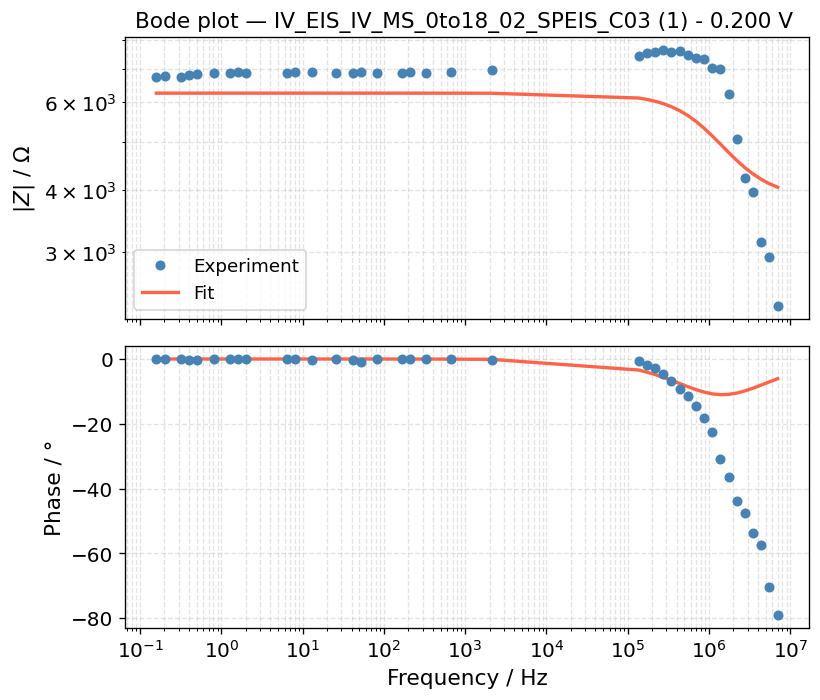

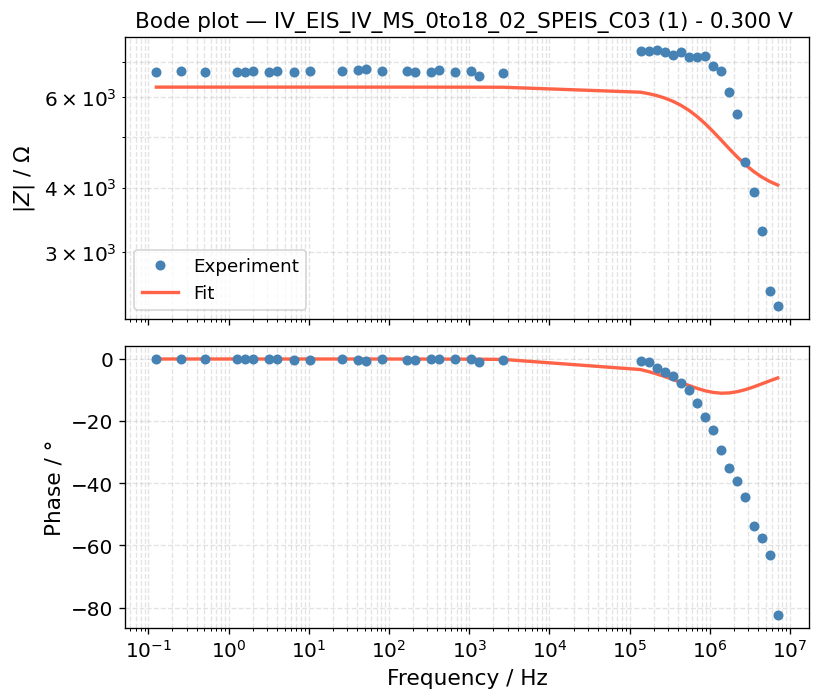

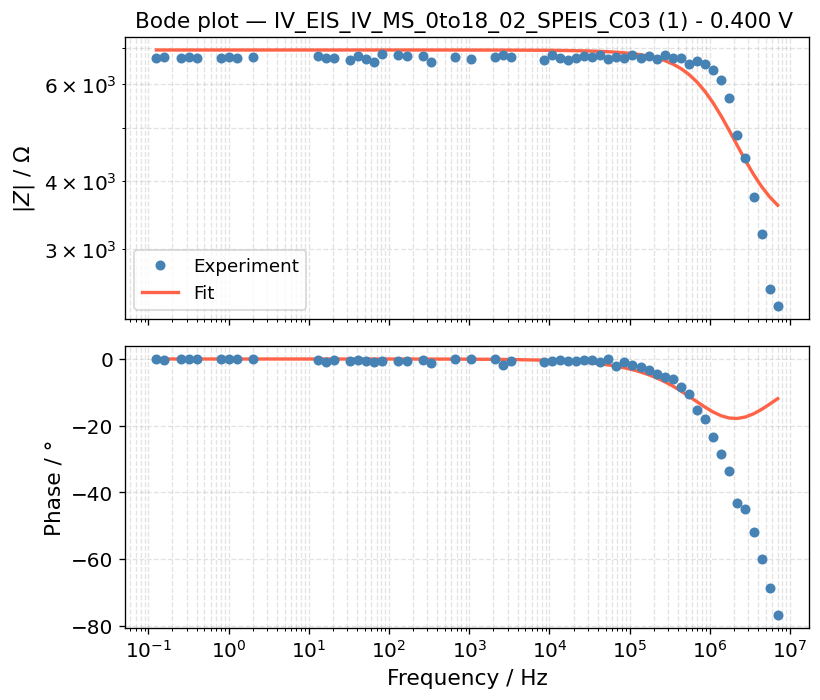

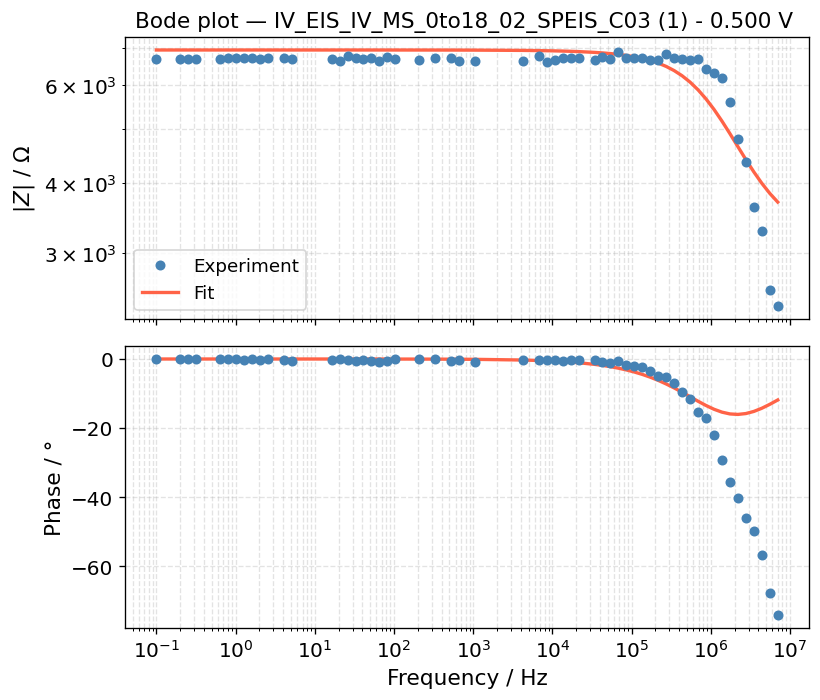

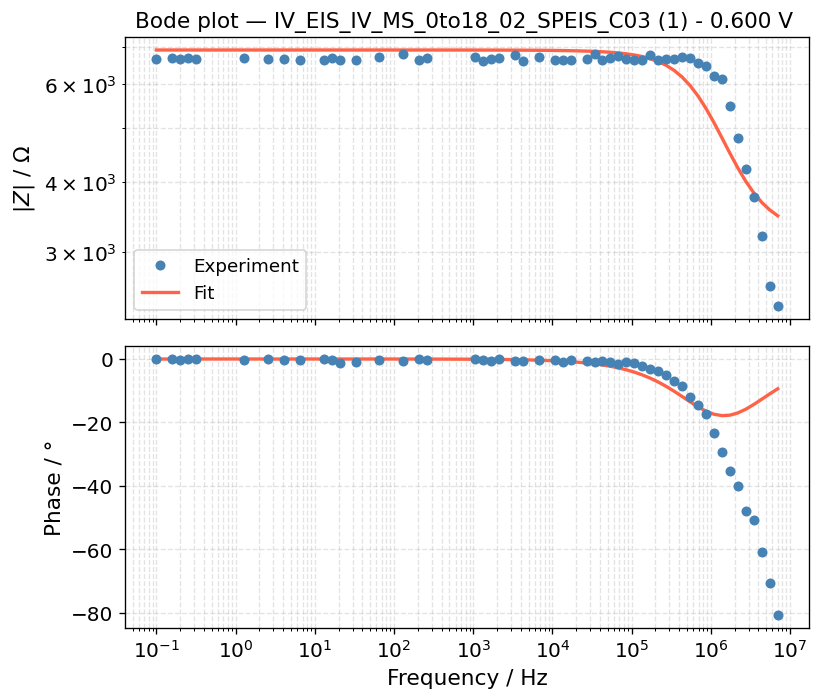

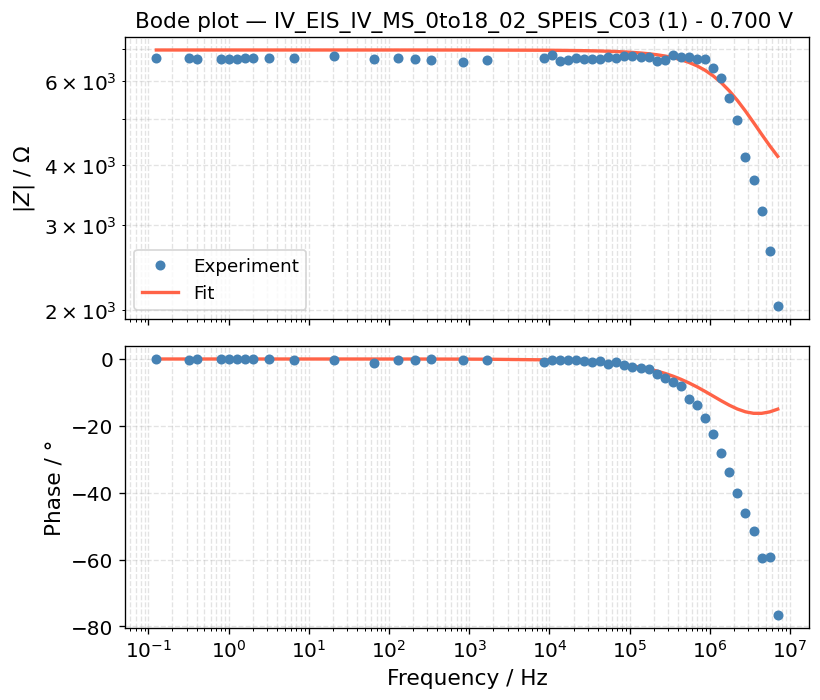

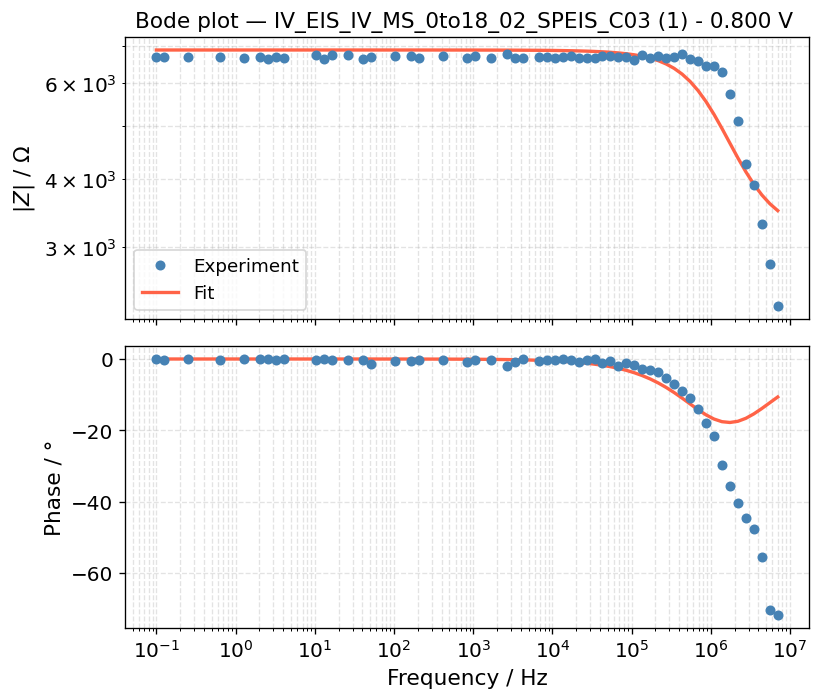

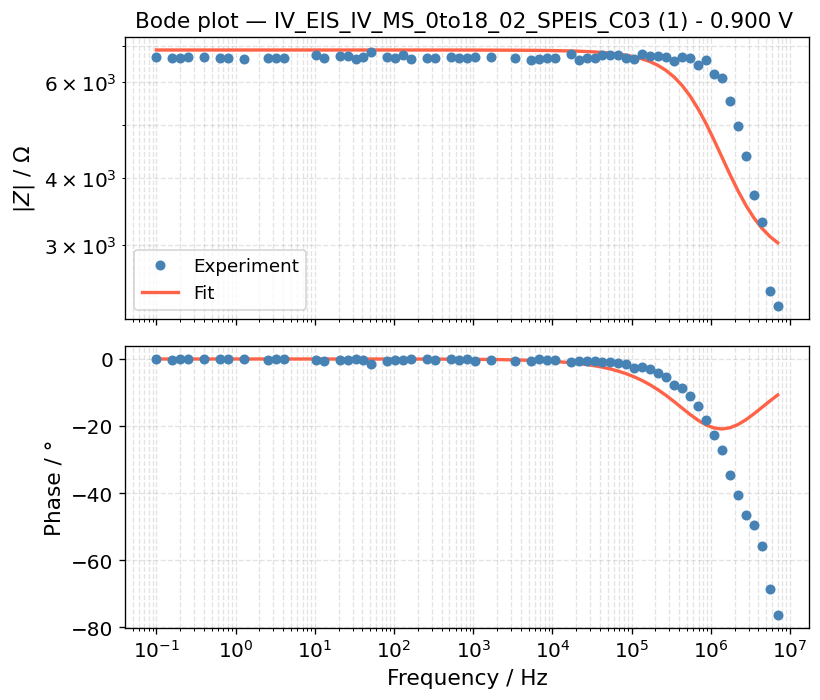

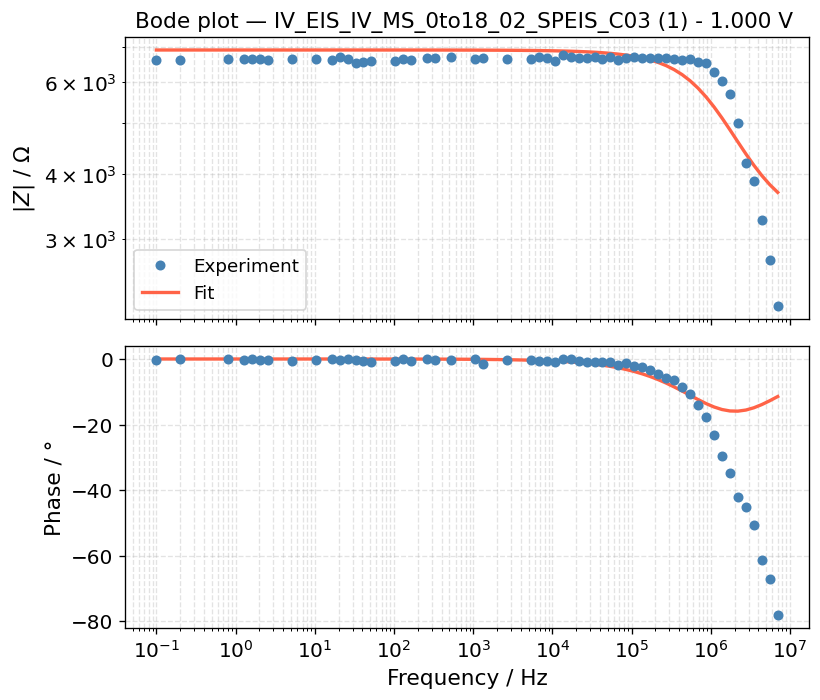

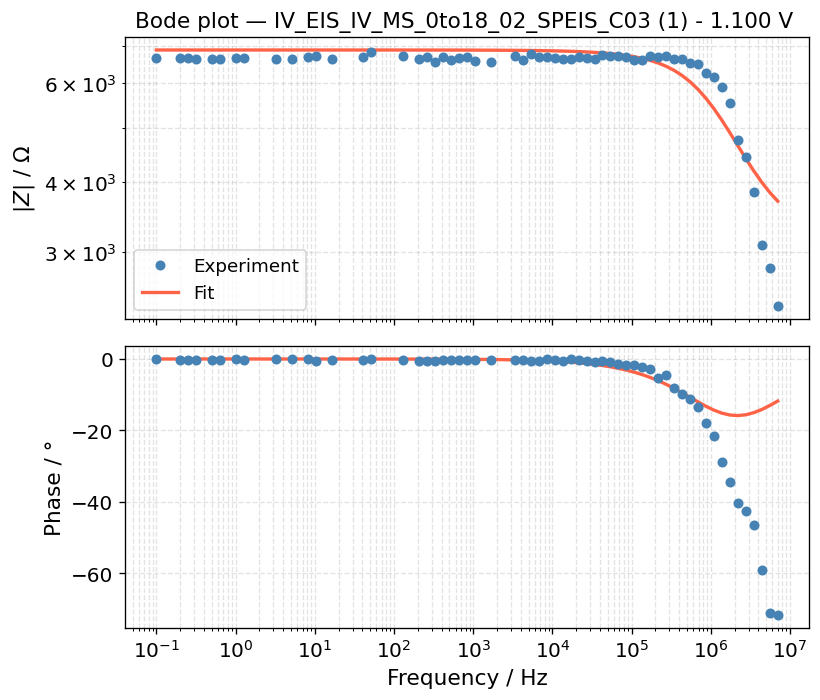

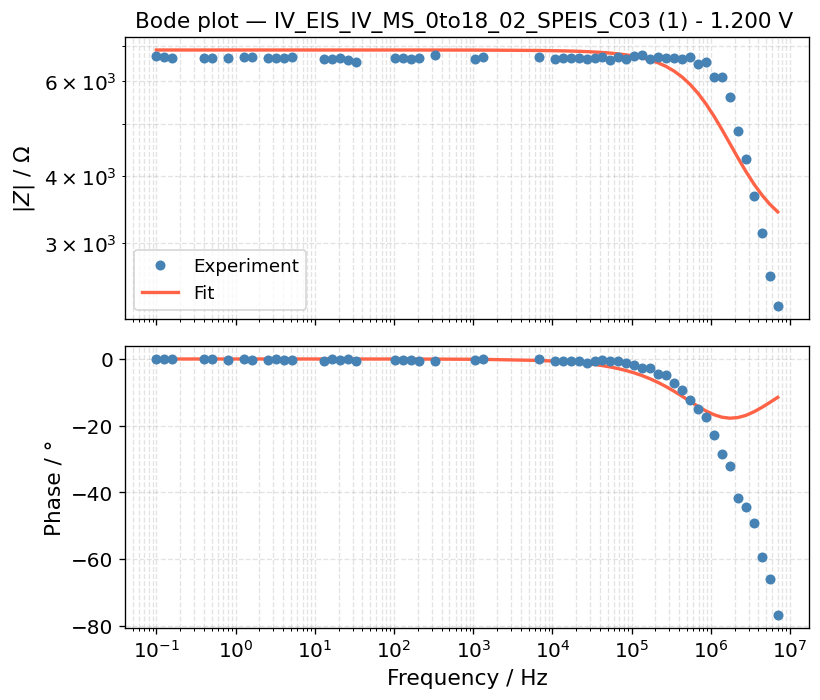

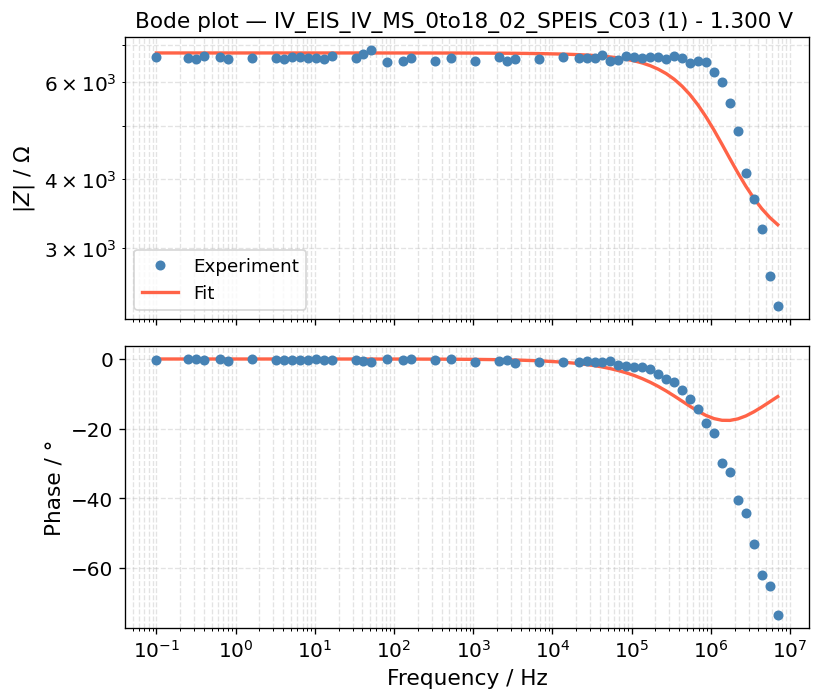

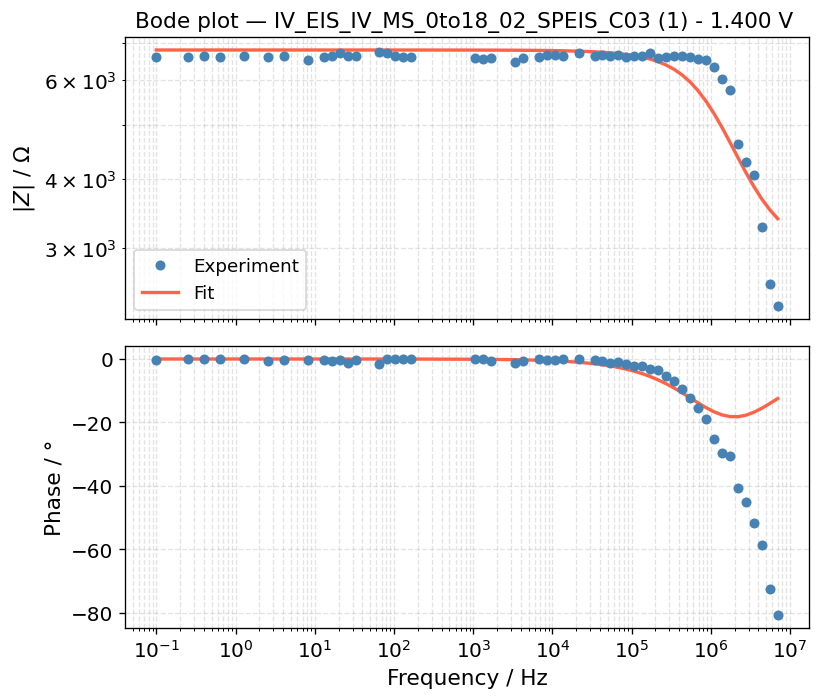

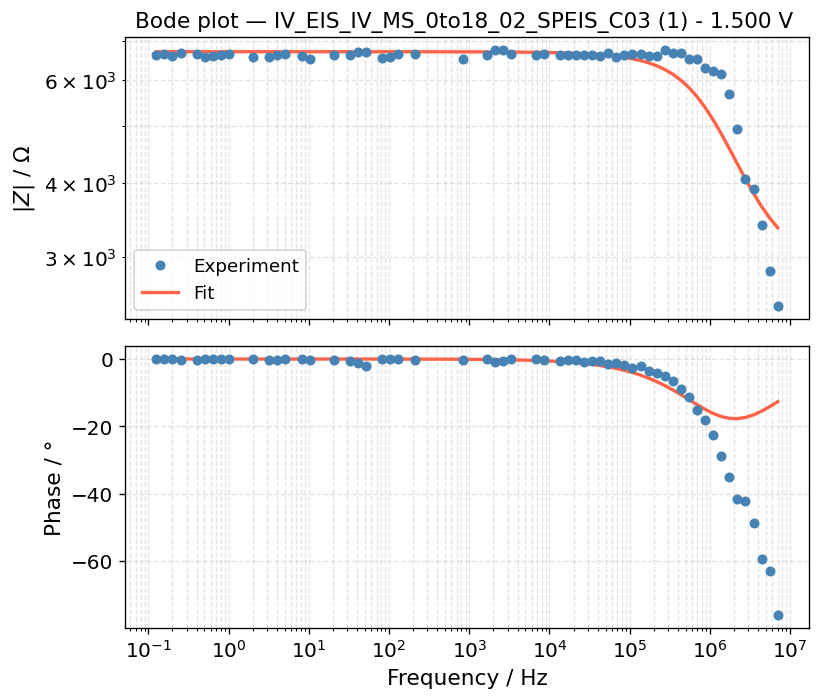

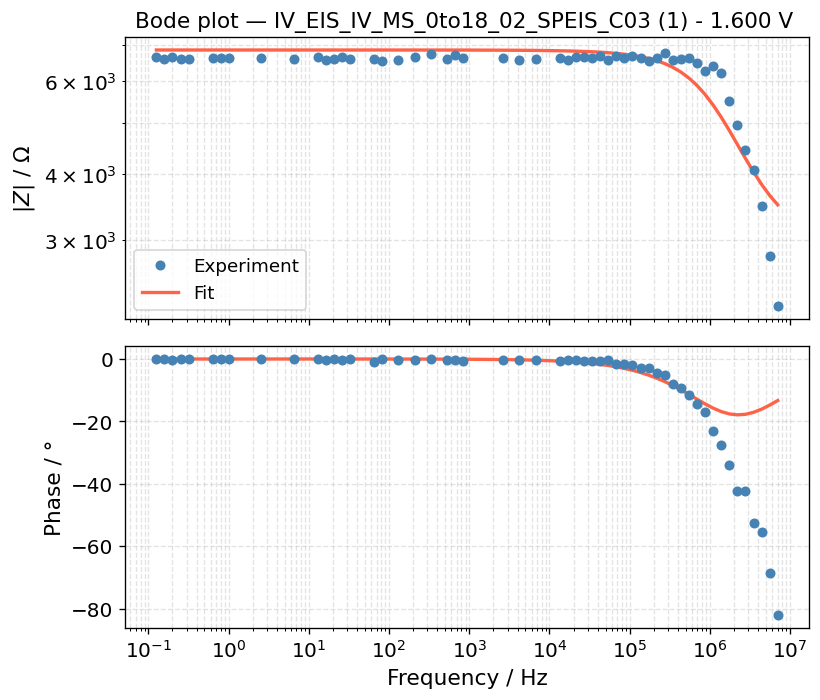

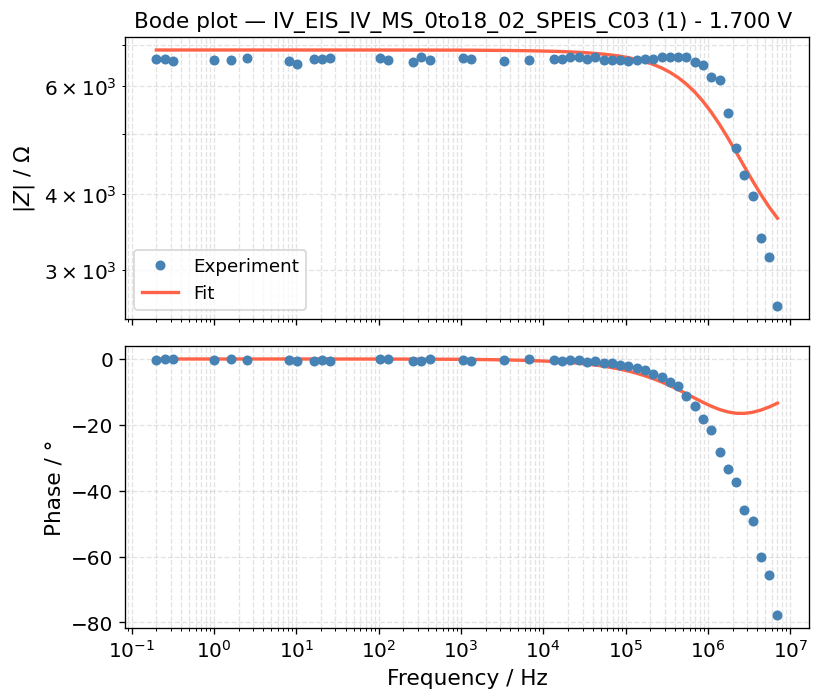

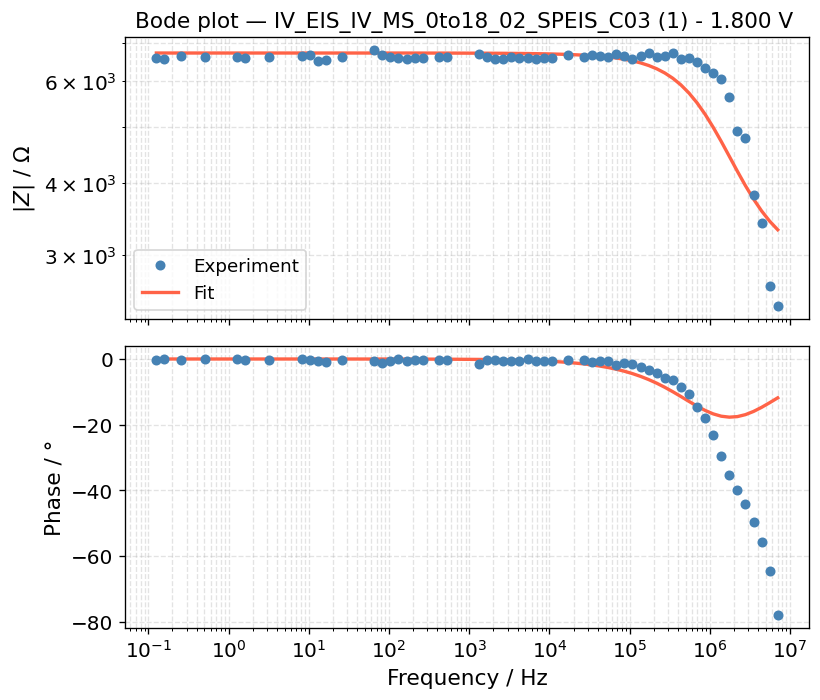

In [29]:
for cyc, sp in clean_spectra.items():
    frequencies_clean = sp["freq"]
    Z_clean = sp["Z"]
    circuit = sp["circuit"]

    # ── Generate fitted impedance and call plot ───────────────────────────────────
    Z_fit = circuit.predict(frequencies_clean)

    fig, (ax_mod, ax_ph) = plt.subplots(2, 1, figsize=(7, 6), sharex=True)

    # |Z| vs frequency
    ax_mod.loglog(frequencies_clean, np.abs(Z_clean), "o", ms=5, color="steelblue",
                  label="Experiment", zorder=3)
    ax_mod.loglog(frequencies_clean, np.abs(Z_fit), "-", lw=2, color="tomato",
                  label="Fit", zorder=2)
    ax_mod.set_ylabel(r"$|Z|$ / Ω", fontsize=13)
    ax_mod.legend(fontsize=11)
    ax_mod.grid(True, which="both", linestyle="--", alpha=0.35)
    ax_mod.set_title(f"Bode plot — {Path(FILE_PATH).stem} - {sp['voltage']:.3f} V ", fontsize=13)

    # Phase vs frequency
    phase_data = np.angle(Z_clean, deg=True)
    phase_fit  = np.angle(Z_fit, deg=True)
    ax_ph.semilogx(frequencies_clean, phase_data, "o", ms=5, color="steelblue", zorder=3)
    ax_ph.semilogx(frequencies_clean, phase_fit, "-", lw=2, color="tomato", zorder=2)
    ax_ph.set_xlabel("Frequency / Hz", fontsize=13)
    ax_ph.set_ylabel("Phase / °", fontsize=13)
    ax_ph.grid(True, which="both", linestyle="--", alpha=0.35)

    plt.tight_layout()
    plt.show()

---
## 9 — Parameter Summary & Derived Quantities

For each RC arc $i$ the following quantities are derived from the CPE parameters:

| Quantity | Formula |
|----------|---------|
| Effective capacitance | $C_{\text{eff},i} = Q_i^{1/\alpha_i} \cdot R_i^{(1-\alpha_i)/\alpha_i}$ |
| Time constant | $\tau_i = R_i \cdot C_{\text{eff},i} = R_i^{1/\alpha_i} \cdot Q_i^{1/\alpha_i}$ |

These are the standard conversions from the Hahn–Bard (2001) formulation.

In [ ]:
# Initialize an empty list to store data for each cycle
all_cycle_summary_data = []

# Loop through each cleaned spectrum (which now includes the fitted circuit)
for cyc, sp in clean_spectra.items():
    circuit = sp["circuit"] # Retrieve the fitted circuit from the spectrum data
    voltage = sp["voltage"] # Retrieve the voltage for the current cycle

    # Prepare a dictionary for the current cycle's data
    cycle_data = {
        "Cycle": cyc,
        "Voltage (V)": voltage
    }

    # ── Fitted parameter table data for the current cycle ─────────────────────────
    param_names_fit, _ = circuit.get_param_names() # No need for units in summary df
    params = circuit.parameters_
    errors = circuit.conf_

    for name, val, err in zip(param_names_fit, params, errors):
        cycle_data[name] = val
        cycle_data[f"{name}_err"] = err
        cycle_data[f"{name}_rel_err_pc"] = (err / abs(val) * 100) if val != 0 else np.nan

    # Add frozen parameters (if any)
    for name, val in FROZEN_PARAMS.items():
        if name not in cycle_data: # Ensure we don't overwrite if it was also a fitted param
            cycle_data[name] = val
            cycle_data[f"{name}_err"] = 0.0 # Frozen params have 0 error
            cycle_data[f"{name}_rel_err_pc"] = "FROZEN"

    # ── Derived quantities per arc for the current cycle ──────────────────────────
    # Collect all fitted + frozen params in one dict for easy lookup
    all_fitted_current_cycle: dict[str, float] = dict(zip(param_names_fit, params))
    all_fitted_current_cycle.update(FROZEN_PARAMS)

    # Print header for derived quantities for each cycle for clarity in output
    print(f"\nCycle {cyc:.0f} (Voltage: {voltage:.3f} V) - Derived quantities per RC arc:")
    print(f"  {'Arc':<6}  {'R [Ω]':>12}  {'Q [S·sᵅ]':>12}  {'α':>6}  {'C_eff [F]':>12}  {'τ [s]':>12}  {'f_peak [Hz]':>12}")
    print("  " + "-" * 74)

    for i in range(1, N_RC + 1):
        R_key  = f"R{i}"
        Q_key  = f"CPE{i}_0"
        a_key  = f"CPE{i}_1"

        R = all_fitted_current_cycle.get(R_key)
        Q = all_fitted_current_cycle.get(Q_key)
        a = all_fitted_current_cycle.get(a_key)

        if None in (R, Q, a):
            continue

        C_eff = Q ** (1.0 / a) * R ** ((1.0 - a) / a)
        tau   = R * C_eff
        f_peak = 1.0 / (2 * np.pi * tau)

        cycle_data[f"C_eff_arc{i}"] = C_eff
        cycle_data[f"tau_arc{i}"] = tau
        cycle_data[f"f_peak_arc{i}"] = f_peak

        print(f"  Arc {i}   {R:>12.3e}  {Q:>12.3e}  {a:>6.3f}  {C_eff:>12.3e}  {tau:>12.3e}  {f_peak:>12.3e}")

    # Add the current cycle's data to the list
    all_cycle_summary_data.append(cycle_data)

# Convert the list of dictionaries to a pandas DataFrame
df_summary = pd.DataFrame(all_cycle_summary_data)

# Display the full summary DataFrame
print("\n" + "═" * 80)
print("  Full Summary of Fitted Parameters and Derived Quantities across all Cycles")
print("═" * 80)
display(df_summary)


In [ ]:
# ── Fitted parameters vs DC Bias ──────────────────────────────────────────────
voltages_fit = df_summary["Voltage (V)"].values.astype(float)
pnames_to_plot = list(param_names_fit)

ncols_p = 2
nrows_p = int(np.ceil(len(pnames_to_plot) / ncols_p))

fig, axes_p = plt.subplots(nrows_p, ncols_p,
                            figsize=(ncols_p * 5, nrows_p * 3.5),
                            constrained_layout=True)
axes_p_flat = axes_p.flatten() if hasattr(axes_p, "flatten") else [axes_p]

for ax_p, pname in zip(axes_p_flat, pnames_to_plot):
    vals = df_summary[pname].values
    err_col = f"{pname}_err"
    errs_p = df_summary[err_col].values if err_col in df_summary.columns \
             else np.zeros(len(vals))
    ax_p.errorbar(voltages_fit, vals, yerr=errs_p,
                  fmt="o-", ms=6, lw=1.5, capsize=4)
    ax_p.set_xlabel("Voltage (V)", fontsize=11)
    ax_p.set_ylabel(pname, fontsize=11)
    ax_p.set_title(pname, fontsize=12)
    ax_p.grid(True, linestyle="--", alpha=0.35)

for ax_p in axes_p_flat[len(pnames_to_plot):]:
    ax_p.set_visible(False)

fig.suptitle(f"Fitted parameters vs DC Bias — {Path(FILE_PATH).stem}", fontsize=13)
plt.show()

---
## 9 — Mott-Schottky Analysis

The Mott-Schottky (MS) plot uses the voltage-dependent depletion capacitance to characterise the semiconductor in the device:

$$\frac{1}{C_\text{dep}^2}(V) = \frac{2}{q\,\varepsilon_r\varepsilon_0\,N\,A^2}\!\left(V - V_{fb} - \frac{k_BT}{q}\right)$$

| Extracted quantity | From |
|---|---|
| Carrier density $N$ (donors $N_D$ or acceptors $N_A$) | Slope of $1/C^2$ vs $V$ |
| Flat-band voltage $V_{fb}$ | $x$-intercept minus $k_BT/q \approx 26\,\text{mV}$ |
| Semiconductor type | Sign of slope: positive → n-type, negative → p-type |

**What to set:**
1. `MS_ARC` — the arc whose $C_\text{eff}$ represents the depletion layer (usually arc 1).
2. `MS_EPSILON_R` — relative permittivity of the absorber/semiconductor layer.
3. `MS_AREA_CM2` — contact or illumination area in cm².  
   *The density $N$ scales as $A^{-2}$, so this is the most critical input.*
4. `MS_FIT_V_MIN / MS_FIT_V_MAX` — narrow the window if the plot is non-linear at the extremes.


In [ ]:
# ═══════════════════════════════════════════════════════════════════
#  MOTT-SCHOTTKY CONFIGURATION — edit values in this cell
# ═══════════════════════════════════════════════════════════════════

# ── Which RC arc carries the junction / depletion capacitance ────────────────
# Arc 1 (lowest-frequency arc) is usually the space-charge layer in
# metal/semiconductor or p-n junctions.
MS_ARC = 1

# ── Material parameters ───────────────────────────────────────────────────────
MS_EPSILON_R = 10.0   # relative dielectric permittivity of the semiconductor
                      # (e.g. 11.7 Si, 12.9 GaAs, 10 CuInSe₂, 8-10 Cu₂O)
MS_AREA_CM2  = 0.01   # illuminated/contact area in cm²  ← adjust for your device

# ── Voltage window for the linear fit ────────────────────────────────────────
# Set both to None to use all measured voltages.
# Narrow the window if the 1/C² curve shows curvature at the extremes
# (e.g. deep depletion at large reverse bias, or minority-carrier effects near V_fb).
MS_FIT_V_MIN = None   # lower bound (V), inclusive  — e.g. -0.5
MS_FIT_V_MAX = None   # upper bound (V), inclusive  — e.g.  0.0

# ── Measurement temperature ───────────────────────────────────────────────────
MS_TEMP_K = 300.0     # temperature in Kelvin (for the kT/q correction to V_fb)


In [ ]:
# ── Mott-Schottky plot: 1/C_eff² vs Voltage ──────────────────────────────────
_col = f"C_eff_arc{MS_ARC}"
if _col not in df_summary.columns:
    raise ValueError(
        f"Column '{_col}' not found in df_summary. "
        f"Ensure N_RC >= {MS_ARC} and the summary cell has been run."
    )

voltages_ms = df_summary["Voltage (V)"].values.astype(float)
C_eff_ms    = df_summary[_col].values.astype(float)
inv_C2      = 1.0 / C_eff_ms**2          # F⁻²

# ── Select voltage window for the linear fit ──────────────────────────────────
v_lo = MS_FIT_V_MIN if MS_FIT_V_MIN is not None else voltages_ms.min()
v_hi = MS_FIT_V_MAX if MS_FIT_V_MAX is not None else voltages_ms.max()
mask_fit = (voltages_ms >= v_lo) & (voltages_ms <= v_hi)
V_fit    = voltages_ms[mask_fit]
iC2_fit  = inv_C2[mask_fit]

if len(V_fit) < 2:
    raise ValueError("Too few points in the selected voltage window for a linear fit — "
                     "adjust MS_FIT_V_MIN / MS_FIT_V_MAX.")

# ── Linear regression: 1/C² = slope × V + intercept ─────────────────────────
slope, intercept = np.polyfit(V_fit, iC2_fit, 1)
V_line   = np.linspace(V_fit.min(), V_fit.max(), 300)
iC2_line = slope * V_line + intercept

# ── Physical constants and unit conversion ────────────────────────────────────
_q    = 1.602176634e-19   # elementary charge [C]
_eps0 = 8.8541878128e-12  # vacuum permittivity [F/m]
_kTq  = 1.380649e-23 * MS_TEMP_K / _q   # thermal voltage [V]
_A_m2 = MS_AREA_CM2 * 1e-4              # area [m²]

# N from slope:  slope = 2 / (q ε_r ε_0 N A²)  →  N = 2 / (q ε_r ε_0 A² |slope|)
N_cm3 = abs(2.0 / (_q * MS_EPSILON_R * _eps0 * _A_m2**2 * slope)) * 1e-6  # → cm⁻³

# Flat-band voltage: x-intercept of the linear fit minus kT/q
V_xint = -intercept / slope
V_fb   = V_xint - _kTq     # subtract kT/q (holds for both n- and p-type)

carrier_type = "n-type (donors, N_D)" if slope > 0 else "p-type (acceptors, N_A)"

print(f"╔{'═'*56}╗")
print(f"║  Mott-Schottky Analysis — arc {MS_ARC}  ({_col}){'':14}║")
print(f"╠{'═'*56}╣")
print(f"║  Semiconductor type  : {carrier_type:<33}║")
print(f"║  Slope               = {slope:>+.4e}  F⁻² V⁻¹{'':8}║")
print(f"║  x-intercept         = {V_xint:>+.4f} V{'':25}║")
print(f"║  kT/q (at {MS_TEMP_K:.0f} K)     = {_kTq:>+.4f} V{'':25}║")
print(f"║  V_fb                = {V_fb:>+.4f} V{'':25}║")
print(f"║  N                   = {N_cm3:>8.3e} cm⁻³{'':19}║")
print(f"╠{'═'*56}╣")
print(f"║  Device: ε_r = {MS_EPSILON_R}, A = {MS_AREA_CM2} cm²  (edit MS config cell){'':7}║")
print(f"╚{'═'*56}╝")

# ── Scale factor for readable y-axis ─────────────────────────────────────────
# C_eff ≈ 10–30 nF  →  1/C² ≈ 10¹⁵ F⁻²  → scale × 1e-15 gives values ≈ 1–5
_yscale = 1e-15
_ylabel = r"$1/C_\mathrm{eff}^2 \;(\times 10^{15}\,\mathrm{F}^{-2})$"

fig_ms, ax_ms = plt.subplots(figsize=(7, 5))

ax_ms.plot(voltages_ms, inv_C2 * _yscale,
           "o", ms=9, color="steelblue",
           label=r"$1/C_\mathrm{eff}^2$  (arc %d)" % MS_ARC)
ax_ms.plot(V_line, iC2_line * _yscale,
           "--", lw=2, color="tomato",
           label=f"Linear fit  (N = {N_cm3:.2e} cm⁻³)")
ax_ms.axvline(V_fb, color="dimgray", lw=1.3, ls=":",
              label=f"$V_{{fb}}$ = {V_fb:+.3f} V")
ax_ms.axhline(0, color="black", lw=0.6)

# Shade the region used for the fit
ax_ms.axvspan(V_fit.min(), V_fit.max(), alpha=0.07, color="tomato",
              label="Fit window")

ax_ms.set_xlabel("DC Bias $V$ (V)", fontsize=13)
ax_ms.set_ylabel(_ylabel, fontsize=13)
ax_ms.set_title(
    f"Mott-Schottky — {Path(FILE_PATH).stem}\n"
    f"N = {N_cm3:.2e} cm⁻³,  $V_{{fb}}$ = {V_fb:+.3f} V,  "
    f"$\\varepsilon_r$ = {MS_EPSILON_R},  A = {MS_AREA_CM2} cm²",
    fontsize=11,
)
ax_ms.legend(fontsize=10, loc="upper right")
ax_ms.grid(True, linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()
